# 04 · Forêts aléatoires et gradient boosting : ce que les arbres ajoutent au score de rachat

**Question marketing.** Le marketing veut cibler au plus 10 % de la base avec un e-mail promotionnel. Les modèles d'ensemble à base d'arbres sont-ils meilleurs que la simple règle de récence pour trouver les clients qui rachèteront en août 2020 ? Et que faut-il en retenir pour l'usage du score ?

**Ce que le notebook produit** : les modèles *forêt aléatoire*, *XGBoost* et *LightGBM* comparés sur les **mêmes 5 plis** (`c.get_folds()`, prédictions hors-échantillon), leurs prédictions (`c.save_predictions`), le tableau `results/04_model_comparison.csv`, les meilleurs hyperparamètres `results/04_best_params.json`, l'ablation par famille de variables `results/04_ablation_familles.csv`, des figures `figures/04_*.png` et un résumé `results/04_summary.md`.

**Règles du jeu**
- Les features viennent du notebook 02 (`c.load_features`), sans la cible. La cible ne sert qu'à entraîner et à évaluer.
- **Un seul protocole d'évaluation** : AUC calculée sur les prédictions hors-échantillon des 5 plis communs ; la prédiction du test est la moyenne des 5 modèles de pli. Le test ne sert à **aucune décision**.
- **Réglage dans le cadre du cours** (slide 69) : *random search* puis *grid search* fin, sur un sous-échantillon stratifié de 40 000 clients ; puis évaluation par la validation croisée complète. Ni optimisation bayésienne, ni empilement de modèles, ni encodage par la cible.
- Calcul limité à 5 cœurs (`n_jobs = 5`).

In [1]:
import os, re, time, warnings, json, textwrap
from contextlib import contextmanager
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, ParameterSampler, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
import lightgbm as lgb
import xgboost as xgb

import common as c

warnings.filterwarnings('ignore')
c.set_style()
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 120)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

# ---- budget de calcul (réglé pour ~20 min au total) ----
N_JOBS = 5               # limite imposée (plusieurs notebooks tournent en parallèle)
SUB_N = 40_000           # taille du sous-échantillon stratifié pour les recherches
N_ITER_RF = 18           # configurations testées (random search) pour la forêt
N_ITER_GBM = 30          # configurations testées (random search) pour XGBoost et LightGBM
RF_TREES_MAX = 400       # arbres max pour la courbe « nombre d'arbres »
CURVE_BUDGET = 40        # courbes d'itérations : n_max = CURVE_BUDGET / learning_rate

FIG_MSG = {}             # message de chaque figure (repris dans results/04_summary.md)
STEP_TIMES = {}          # durée de chaque étape


@contextmanager
def timed(name):
    t = time.time(); yield; STEP_TIMES[name] = time.time() - t


def md(s):
    display(Markdown(s))


def fr(x, nd=1):
    return f'{x:,.{nd}f}'.replace(',', ' ').replace('.', ',')


def pc(x, nd=1):
    return fr(100 * x, nd) + ' %'


def nf(x):
    return f'{int(x):,}'.replace(',', ' ')


def a4(x):
    return fr(x, 4)


def sg(x, nd=4):
    # nombre signé au format français
    return f'{x:+.{nd}f}'.replace('.', ',').replace('-', '−')


def done(fig, name, title):
    lines = textwrap.wrap(title, width=int(fig.get_figwidth() * 8.2))
    fig.suptitle('\n'.join(lines), x=0.01, ha='left', fontsize=12.5, fontweight='bold', y=1.0)
    fig.tight_layout(rect=(0, 0, 1, 1 - (0.30 * len(lines) + 0.05) / fig.get_figheight()))
    c.save_fig(fig, name)
    FIG_MSG[name] = title
    plt.show()

## 1. Pourquoi des arbres ici ?

Le notebook 02 l'a montré : le rachat ne dépend pas d'une variable mais de **combinaisons** (la grille récence × fréquence passe de 0,3 % à plus de 30 % de rachat), avec des **effets de seuil** (un achat dans les 7 derniers jours change tout), des **effets non linéaires** (la fréquence compte beaucoup au début puis sature) et des **interactions** (avoir acheté en août 2019 pèse davantage chez un client récent). Un modèle linéaire doit recevoir ces formes toutes faites (classes, produits de variables) ; un arbre les **découvre** en découpant successivement la base (« dernier achat il y a moins de 7 jours ? », puis « plus de 5 tickets sur 90 jours ? »).

*Lien avec le cours* : l'arbre capte les non-linéarités sans normalisation ni préparation lourde, mais il est instable et sur-apprend (slides 58-59). Les **méthodes d'ensemble** corrigent ce défaut de deux façons (slide 60) : le **bagging** moyenne de nombreux arbres indépendants, ce qui réduit la variance (**forêt aléatoire**, slides 61-62) ; le **boosting** ajoute des arbres simples qui corrigent un à un les erreurs des précédents (**XGBoost, LightGBM**, slides 63-64). Le prix à payer : des modèles moins lisibles (importances et dépendance partielle ici, SHAP au notebook 06) et de nombreux hyperparamètres à régler (slide 69).

In [2]:
Xtr_raw = c.load_features('train'); Xte_raw = c.load_features('test')
y = c.load_target().loc[Xtr_raw.index]
folds = c.get_folds().loc[Xtr_raw.index]
yv, fold = y.to_numpy(), folds.to_numpy()
BASE_RATE = yv.mean()
assert list(Xtr_raw.columns) == list(Xte_raw.columns)

dico = pd.read_csv(c.RES / '02_feature_dictionary.csv')
dico = dico[dico['kept']].set_index('name')
GROUPS = list(dict.fromkeys(dico['group']))
log_cols = [k for k in Xtr_raw.columns if k.startswith('log_')]
base_cols = [k for k in Xtr_raw.columns if not k.startswith('log_')]
cat_cols = [k for k in base_cols if not pd.api.types.is_numeric_dtype(Xtr_raw[k])]
levels = {k: sorted(Xtr_raw[k].unique()) for k in cat_cols}
na_cols = [k for k in base_cols if Xtr_raw[k].isna().any()]

# repère : la règle de récence seule (score = - jours depuis le dernier achat)
score_rec = (-Xtr_raw['recency_days']).fillna(-1e3)
rep_rec = c.cv_report(y, score_rec, folds)

md(f'''
| | |
|---|---|
| Clients train / test | **{nf(len(Xtr_raw))}** / **{nf(len(Xte_raw))}** |
| Rachat en août 2020 (train) | **{pc(BASE_RATE)}** ({nf(yv.sum())} clients) |
| Variables du notebook 02 | {Xtr_raw.shape[1]} dont {len(log_cols)} jumeaux `log_*`, {len(cat_cols)} qualitatives, {len(na_cols)} avec valeurs manquantes structurelles |
| Repère : règle de récence seule | AUC **{a4(rep_rec['auc'])}**, top 10 % : précision {pc(rep_rec['precision_top10'])}, rappel {pc(rep_rec['recall_top10'])}, lift {fr(rep_rec['lift_top10'], 2)} |
''')


| | |
|---|---|
| Clients train / test | **160 424** / **40 106** |
| Rachat en août 2020 (train) | **7,7 %** (12 392 clients) |
| Variables du notebook 02 | 100 dont 19 jumeaux `log_*`, 6 qualitatives, 44 avec valeurs manquantes structurelles |
| Repère : règle de récence seule | AUC **0,8180**, top 10 % : précision 23,5 %, rappel 30,4 %, lift 3,04 |


## 2. Préparation commune aux trois modèles

Trois choix, justifiés par le cours :

1. **On retire les jumeaux `log_*`.** Un arbre ne compare une variable qu'à un seuil : appliquer une transformation croissante (log) ne change ni l'ordre des clients ni les découpes possibles. Les jumeaux ne servent qu'aux modèles linéaires du notebook 03. On le **vérifie** ci-dessous (même AUC avec et sans jumeaux) ; les garder diluerait seulement les tirages de variables de la forêt (`max_features`) et du boosting (`colsample_bytree`).
2. **One-hot « N − 1 »** pour les 6 variables qualitatives (`price_segment`, `main_store_region`, `civility`, `email_domain`, `email_type`, `dept`), comme dans le cours (slides 85-88). L'usage natif des catégories par LightGBM est une piste d'amélioration, notée en fin de notebook mais **non utilisée ici** : tous les modèles voient exactement les mêmes colonnes.
3. **Valeurs manquantes** : XGBoost et LightGBM les gèrent seuls (ils apprennent de quel côté du seuil envoyer un manquant). Pour la **forêt de scikit-learn**, on suit le cours : imputation par la **médiane** (calculée sans la cible) ; l'information « non défini » reste portée par les indicateurs déjà fournis (`is_one_shot`, `has_interval_std`, `has_card`).

*Lien avec le cours* : préparation des variables (slides 85-88) : one-hot N − 1, imputation par la médiane, pas de standardisation pour les arbres.

In [3]:
def encode(X, cols):
    # one-hot N-1 des qualitatives (1er niveau = référence), colonnes float32 ; mapping variable d'origine -> colonnes
    parts, mapping = [], {}
    for k in cols:
        if k in cat_cols:
            d = pd.DataFrame({f'{k}__{re.sub(r"[^0-9A-Za-z]+", "_", str(l))}': (X[k].to_numpy() == l).astype('float32')
                              for l in levels[k][1:]}, index=X.index)
            parts.append(d); mapping[k] = list(d.columns)
        else:
            parts.append(X[[k]].astype('float32')); mapping[k] = [k]
    Z = pd.concat(parts, axis=1)
    assert Z.columns.is_unique
    return Z, mapping


Z_tr, MAP = encode(Xtr_raw, base_cols)
Z_te, _ = encode(Xte_raw, base_cols)
ENC_COLS = list(Z_tr.columns)
OWNER = {e: k for k, v in MAP.items() for e in v}                       # colonne encodée -> variable d'origine
med = Z_tr.median()
Zi_tr, Zi_te = Z_tr.fillna(med), Z_te.fillna(med)                          # copie imputée pour la forêt
assert not Zi_tr.isna().any().any() and not Zi_te.isna().any().any()
unseen = {k: sorted(set(Xte_raw[k].unique()) - set(levels[k])) for k in cat_cols}
A_tr, A_te, Ai_tr, Ai_te = (M_.to_numpy() for M_ in (Z_tr, Z_te, Zi_tr, Zi_te))
n_nan = int(np.isnan(A_tr).sum())

# Vérification de l'invariance : LightGBM (sans tirage aléatoire de variables) avec et sans jumeaux log
def fold0_auc(A, **kw):
    tr, va = fold != 0, fold == 0
    m = lgb.LGBMClassifier(n_estimators=300, learning_rate=.05, min_child_samples=100, random_state=c.SEED,
                           n_jobs=N_JOBS, verbose=-1, force_row_wise=True, **kw).fit(A[tr], yv[tr])
    return roc_auc_score(yv[va], m.predict_proba(A[va])[:, 1])


Z_log, _ = encode(Xtr_raw, list(Xtr_raw.columns))
auc_nolog, auc_log = fold0_auc(A_tr), fold0_auc(Z_log.to_numpy())
n_log_cols = Z_log.shape[1]
del Z_log

md(f'''
Matrice d'entrée : **{nf(A_tr.shape[0])} clients × {A_tr.shape[1]} colonnes** (dont {A_tr.shape[1] - len(base_cols) + len(cat_cols)} colonnes issues du one-hot des {len(cat_cols)} qualitatives, N − 1 indicatrices chacune), {nf(n_nan)} valeurs manquantes conservées pour XGBoost / LightGBM, matrice imputée par la médiane pour la forêt. Modalités du test absentes du train : {sum(len(v) for v in unseen.values())} (le regroupement en `AUTRE` du notebook 02 les a déjà absorbées).

**Contrôle de l'invariance** (LightGBM, pli 0 en validation) : AUC **{a4(auc_nolog)}** sans les jumeaux log, **{a4(auc_log)}** avec ({n_log_cols} colonnes), écart {fr(abs(auc_log - auc_nolog), 4)} : les jumeaux n'apportent rien aux arbres, on les retire.
''')


Matrice d'entrée : **160 424 clients × 170 colonnes** (dont 95 colonnes issues du one-hot des 6 qualitatives, N − 1 indicatrices chacune), 853 608 valeurs manquantes conservées pour XGBoost / LightGBM, matrice imputée par la médiane pour la forêt. Modalités du test absentes du train : 0 (le regroupement en `AUTRE` du notebook 02 les a déjà absorbées).

**Contrôle de l'invariance** (LightGBM, pli 0 en validation) : AUC **0,8785** sans les jumeaux log, **0,8785** avec (189 colonnes), écart 0,0000 : les jumeaux n'apportent rien aux arbres, on les retire.


In [4]:
# ---------- outils communs : validation croisée sur les 5 plis communs, calibration, importances ----------
RESULTS = {}
LGB_BASE = dict(random_state=c.SEED, n_jobs=N_JOBS, verbose=-1, force_row_wise=True)
XGB_BASE = dict(tree_method='hist', random_state=c.SEED, n_jobs=N_JOBS, verbosity=0)


def make_model(kind, **p):
    if kind == 'lgbm':
        return lgb.LGBMClassifier(**{**LGB_BASE, **p})
    if kind == 'xgb':
        return xgb.XGBClassifier(**{**XGB_BASE, **p})
    return RandomForestClassifier(**{'n_jobs': N_JOBS, 'random_state': c.SEED, **p})


def get_imp(m, n_cols):
    if isinstance(m, lgb.LGBMClassifier):
        return m.booster_.feature_importance('gain').astype(float)
    if isinstance(m, xgb.XGBClassifier):
        s = m.get_booster().get_score(importance_type='total_gain')
        return np.array([s.get(f'f{i}', 0.0) for i in range(n_cols)])
    return m.feature_importances_.astype(float)


def run_cv(name, kind, params, cols=None, imputed=False, keep_fold0=False, store=True):
    # 5 plis communs : un modèle par pli, prédictions hors-échantillon, test = moyenne des 5 modèles
    cols = ENC_COLS if cols is None else cols
    idx = [ENC_COLS.index(e) for e in cols]
    A = (Ai_tr if imputed else A_tr)[:, idx]; B = (Ai_te if imputed else A_te)[:, idx]
    oof, te, secs, imps, m0 = np.zeros(len(A)), np.zeros(len(B)), [], [], None
    for k in range(c.N_FOLDS):
        tr, va = fold != k, fold == k
        t0 = time.time(); m = make_model(kind, **params).fit(A[tr], yv[tr]); secs.append(time.time() - t0)
        oof[va] = m.predict_proba(A[va])[:, 1]; te += m.predict_proba(B)[:, 1] / c.N_FOLDS
        imps.append(get_imp(m, len(cols)))
        if keep_fold0 and k == 0:
            m0 = m
    oof_s, te_s = pd.Series(oof, index=Xtr_raw.index, name=name), pd.Series(te, index=Xte_raw.index, name=name)
    rep = c.cv_report(y, oof_s, folds)
    per_fold = [roc_auc_score(yv[fold == k], oof[fold == k]) for k in range(c.N_FOLDS)]
    imp = pd.DataFrame(imps, columns=cols)
    res = dict(name=name, kind=kind, params=params, oof=oof_s, test=te_s, rep=rep, per_fold=per_fold,
               fit_seconds=float(np.mean(secs)), imp=(imp.div(imp.sum(axis=1), axis=0)).mean(), cols=cols, model0=m0)
    if store:
        RESULTS[name] = res
    return res


def calib_table(p, yy, q=10):
    d = pd.DataFrame({'p': p, 'y': yy})
    d['b'] = pd.qcut(d['p'].rank(method='first'), q, labels=False)
    return d.groupby('b').agg(p=('p', 'mean'), y=('y', 'mean'), n=('y', 'size'))


def calib_stats(p, yy):
    # score moyen / taux observé ; pente de recalibrage (1 = parfait, < 1 = trop confiant) ; erreur de calibration moyenne par décile
    pp = np.clip(p, 1e-6, 1 - 1e-6)
    lo = np.log(pp / (1 - pp)).reshape(-1, 1)
    slope = LogisticRegression(C=1e8, max_iter=300).fit(lo, yy).coef_[0, 0]
    g = calib_table(p, yy)
    return dict(mean_ratio=float(np.mean(p) / np.mean(yy)), slope=float(slope), ece=float((np.abs(g['p'] - g['y']) * g['n']).sum() / g['n'].sum()))


def show_rows(names, label=None):
    rows = []
    for nm in names:
        r = RESULTS[nm]; cs = calib_stats(r['oof'].to_numpy(), yv)
        rows.append({'modèle': nm, 'AUC': r['rep']['auc'], 'moy. plis': r['rep']['auc_fold_mean'], 'écart-type plis': r['rep']['auc_fold_std'],
                     'log-loss': r['rep']['logloss'], 'lift top 10 %': r['rep']['lift_top10'], 'score moyen / taux': cs['mean_ratio'],
                     'pente calibr.': cs['slope'], 's par pli': r['fit_seconds']})
    d = pd.DataFrame(rows).set_index('modèle')
    display(d.style.format({'AUC': '{:.4f}', 'moy. plis': '{:.4f}', 'écart-type plis': '{:.4f}', 'log-loss': '{:.4f}', 'lift top 10 %': '{:.2f}',
                            'score moyen / taux': '{:.2f}', 'pente calibr.': '{:.2f}', 's par pli': '{:.1f}'}))
    return d


# sous-échantillon stratifié pour les recherches d'hyperparamètres (tiré une fois pour toutes) et 3 plis internes
sub_idx, _ = train_test_split(np.arange(len(yv)), train_size=SUB_N, stratify=yv, random_state=c.SEED)
ys = yv[sub_idx]
inner = list(StratifiedKFold(3, shuffle=True, random_state=c.SEED).split(sub_idx, ys))
md(f'''Sous-échantillon de recherche : **{nf(len(sub_idx))} clients** tirés au hasard et stratifiés sur la cible (taux de rachat {pc(ys.mean())}, comme la base), découpés en **3 plis internes** identiques pour toutes les configurations. Les recherches se font ici ; l'évaluation finale de chaque modèle se fait ensuite sur les **5 plis complets**.''')

Sous-échantillon de recherche : **40 000 clients** tirés au hasard et stratifiés sur la cible (taux de rachat 7,7 %, comme la base), découpés en **3 plis internes** identiques pour toutes les configurations. Les recherches se font ici ; l'évaluation finale de chaque modèle se fait ensuite sur les **5 plis complets**.

## 3. Forêt aléatoire

Une forêt moyenne de nombreux arbres profonds, chacun entraîné sur un échantillon bootstrap de clients et, à chaque découpe, sur un **sous-ensemble tiré au hasard de variables** (slides 61-62). Hyperparamètres qui comptent : le **nombre d'arbres** (plus il y en a, plus la moyenne est stable, avec un plateau), la **profondeur / taille minimale des feuilles** (une feuille de quelques clients est du bruit), `max_features` (la part de variables tirée à chaque découpe : plus elle est faible, plus les arbres sont différents) et, pour le déséquilibre, `class_weight`.

Démarche : (1) la forêt **non réglée** (valeurs par défaut de scikit-learn) ; (2) un **random search** sur le sous-échantillon ; (3) la courbe « nombre d'arbres » pour fixer la taille de la forêt ; (4) la **validation croisée complète** de la forêt réglée ; (5) l'effet de `class_weight`.

*Lien avec le cours* : forêt aléatoire (slides 61-62) ; réglage par random search (slide 69) ; validation croisée (slide 68).

In [5]:
with timed('RF : forêt non réglée (CV 5 plis)'):
    rf_def = run_cv('rf_default', 'rf', dict(n_estimators=100), imputed=True)
show_rows(['rf_default'])
md(f'''La forêt **non réglée** (100 arbres, feuilles d'un seul client, scikit-learn par défaut) atteint une AUC de **{a4(rf_def['rep']['auc'])}**, déjà au-dessus de la règle de récence ({a4(rep_rec['auc'])}). Son log-loss est mauvais : des arbres entièrement développés rendent des probabilités proches de 0 ou 1, bien trop tranchées. On ne peut pas lire ce score comme une probabilité, seulement comme un classement.''')

,AUC,moy. plis,écart-type plis,log-loss,lift top 10 %,score moyen / taux,pente calibr.,s par pli
modèle,,,,,,,,
rf_default,0.8628,0.8629,0.0021,0.2106,5.07,1.07,0.79,5.8


La forêt **non réglée** (100 arbres, feuilles d'un seul client, scikit-learn par défaut) atteint une AUC de **0,8628**, déjà au-dessus de la règle de récence (0,8180). Son log-loss est mauvais : des arbres entièrement développés rendent des probabilités proches de 0 ou 1, bien trop tranchées. On ne peut pas lire ce score comme une probabilité, seulement comme un classement.

In [6]:
# Random search sur le sous-échantillon : AUC moyenne sur les 3 plis internes (forêt de 100 arbres, médiane déjà imputée)
As_i = Ai_tr[sub_idx]
SPACE_RF = dict(max_features=['sqrt', .15, .3, .5], min_samples_leaf=[3, 10, 25, 50, 100, 200],
                max_depth=[None, 10, 16, 24], max_samples=[None, .5, .7])
rows = []
with timed('RF : random search (sous-échantillon)'):
    for p in ParameterSampler(SPACE_RF, N_ITER_RF, random_state=c.SEED):
        t0 = time.time(); aucs = []
        for tr, va in inner:
            m = make_model('rf', n_estimators=100, **p).fit(As_i[tr], ys[tr])
            aucs.append(roc_auc_score(ys[va], m.predict_proba(As_i[va])[:, 1]))
        rows.append({**p, 'auc_3plis': np.mean(aucs), 'écart-type': np.std(aucs), 'secondes': time.time() - t0})
rf_search = pd.DataFrame(rows).sort_values('auc_3plis', ascending=False).reset_index(drop=True)
display(rf_search.head(8).style.format({'auc_3plis': '{:.4f}', 'écart-type': '{:.4f}', 'secondes': '{:.1f}'}))
rf_best = {k: (None if pd.isna(rf_search.loc[0, k]) else rf_search.loc[0, k]) for k in SPACE_RF}
for k in ('min_samples_leaf', 'max_depth'):
    if rf_best[k] is not None: rf_best[k] = int(rf_best[k])
rf_best = {k: (float(v) if isinstance(v, (float, np.floating)) else v) for k, v in rf_best.items()}
md(f'''Meilleure configuration sur le sous-échantillon : `{rf_best}` (AUC {a4(rf_search.loc[0, 'auc_3plis'])} ; la configuration la moins bonne de la recherche : {a4(rf_search['auc_3plis'].min())}).''')

,min_samples_leaf,max_samples,max_features,max_depth,auc_3plis,écart-type,secondes
0,50,0.700000,0.300000,16.000000,0.8695,0.0030,6.8
1,100,nan,0.300000,24.000000,0.8693,0.0024,6.2
2,25,0.500000,0.300000,10.000000,0.8690,0.0024,19.3
3,50,0.700000,0.150000,nan,0.8685,0.0019,58.2
4,50,0.500000,0.300000,nan,0.8684,0.0023,3.9
5,25,nan,0.500000,nan,0.8684,0.0023,22.5
6,50,0.500000,0.500000,24.000000,0.8682,0.0026,10.5
7,100,0.500000,0.300000,nan,0.8678,0.0026,3.6


Meilleure configuration sur le sous-échantillon : `{'max_features': 0.3, 'min_samples_leaf': 50, 'max_depth': 16, 'max_samples': 0.7}` (AUC 0,8695 ; la configuration la moins bonne de la recherche : 0,8596).

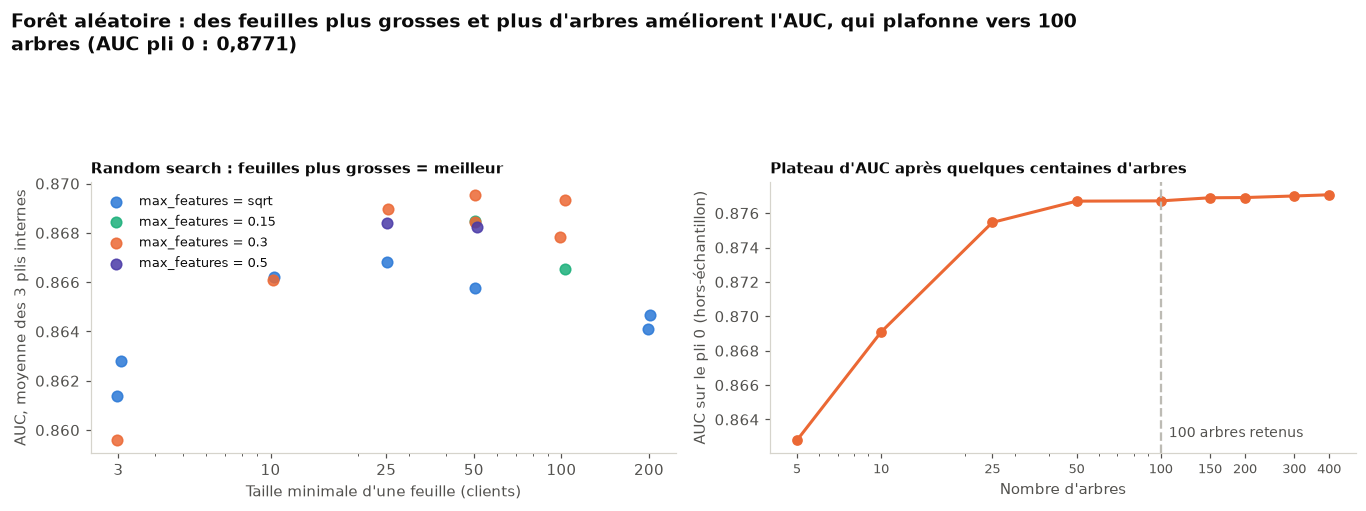

In [7]:
# Nombre d'arbres : AUC sur le pli 0 (modèle entraîné sur les 4 autres plis) quand on moyenne les n premiers arbres
tr0, va0 = fold != 0, fold == 0
with timed('RF : courbe du nombre d\'arbres'):
    m_big = make_model('rf', n_estimators=RF_TREES_MAX, **rf_best).fit(Ai_tr[tr0], yv[tr0])
    P = np.column_stack([t.predict_proba(Ai_tr[va0].astype('float32'))[:, 1] for t in m_big.estimators_])
ns = [n for n in (5, 10, 25, 50, 100, 150, 200, 300, 400) if n <= RF_TREES_MAX]
auc_n = pd.Series({n: roc_auc_score(yv[va0], P[:, :n].mean(axis=1)) for n in ns})
N_TREES = int(auc_n.index[(auc_n >= auc_n.max() - .0005).to_numpy().argmax()])       # 1er n dans 0,0005 point du plateau
N_TREES = max(N_TREES, 100)
del m_big, P

fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.6))
ax = axs[0]
sc = rf_search.copy(); sc['mf'] = sc['max_features'].astype(str)
for mf, col in zip(['sqrt', '0.15', '0.3', '0.5'], [c.BLUE, c.GREEN, c.ACCENT, c.PURPLE]):
    s = sc[sc['mf'] == mf]
    ax.scatter(s['min_samples_leaf'] * np.exp(np.random.RandomState(0).uniform(-.06, .06, len(s))), s['auc_3plis'], s=48, color=col, alpha=.85, label=f'max_features = {mf}')
ax.set_xscale('log'); ax.set_xticks([3, 10, 25, 50, 100, 200]); ax.set_xticklabels([3, 10, 25, 50, 100, 200])
ax.set_xlabel('Taille minimale d\'une feuille (clients)'); ax.set_ylabel('AUC, moyenne des 3 plis internes')
ax.set_title('Random search : feuilles plus grosses = meilleur', fontsize=10, loc='left'); ax.legend(frameon=False, fontsize=8.5)
ax = axs[1]
ax.plot(auc_n.index, auc_n.values, marker='o', color=c.ACCENT, lw=2)
ax.axvline(N_TREES, color=c.GREY, ls='--'); ax.text(N_TREES, auc_n.min(), f'  {N_TREES} arbres retenus', va='bottom', fontsize=9, color=c.INK2)
ax.set_xscale('log'); ax.set_xticks(ns); ax.set_xticklabels(ns, fontsize=8.5)
ax.set_xlabel('Nombre d\'arbres'); ax.set_ylabel('AUC sur le pli 0 (hors-échantillon)'); ax.set_title('Plateau d\'AUC après quelques centaines d\'arbres', fontsize=10, loc='left')
done(fig, '04_rf_reglage', f"Forêt aléatoire : des feuilles plus grosses et plus d'arbres améliorent l'AUC, qui plafonne vers {N_TREES} arbres (AUC pli 0 : {a4(auc_n.max())})")
RF_TUNED = dict(n_estimators=N_TREES, **rf_best)

In [8]:
with timed('RF : forêt réglée (CV 5 plis)'):
    rf_tun = run_cv('rf_tuned', 'rf', RF_TUNED, imputed=True)
with timed('RF : forêt réglée + class_weight (CV 5 plis)'):
    rf_cw = run_cv('rf_tuned_cw', 'rf', {**RF_TUNED, 'class_weight': 'balanced_subsample'}, imputed=True)
d_rf = show_rows(['rf_default', 'rf_tuned', 'rf_tuned_cw'])
cs_rf = {n: calib_stats(RESULTS[n]['oof'].to_numpy(), yv) for n in ('rf_default', 'rf_tuned', 'rf_tuned_cw')}
md(f'''**Réglage** : l'AUC passe de {a4(rf_def['rep']['auc'])} à **{a4(rf_tun['rep']['auc'])}** (+{fr(rf_tun['rep']['auc'] - rf_def['rep']['auc'], 4)}), le log-loss de {a4(rf_def['rep']['logloss'])} à {a4(rf_tun['rep']['logloss'])} : les feuilles plus grosses lissent le score. **`class_weight='balanced_subsample'`** (chaque client rachetant pèse environ {fr((1 - BASE_RATE) / BASE_RATE, 1)} fois plus) donne une AUC de {a4(rf_cw['rep']['auc'])} ({'+' if rf_cw['rep']['auc'] >= rf_tun['rep']['auc'] else '−'}{fr(abs(rf_cw['rep']['auc'] - rf_tun['rep']['auc']), 4)}) mais un log-loss de {a4(rf_cw['rep']['logloss'])} : le score moyen devient **{fr(cs_rf['rf_tuned_cw']['mean_ratio'], 1)} fois** le taux réel de rachat (contre {fr(cs_rf['rf_tuned']['mean_ratio'], 2)} sans pondération). Le classement n'a presque pas bougé, les probabilités sont faussées : la pondération n'a d'intérêt que si on veut un classement ; pour lire un score en probabilité, on s'en passe.
''')

,AUC,moy. plis,écart-type plis,log-loss,lift top 10 %,score moyen / taux,pente calibr.,s par pli
modèle,,,,,,,,
rf_default,0.8628,0.8629,0.0021,0.2106,5.07,1.07,0.79,5.8
rf_tuned,0.8754,0.8754,0.0022,0.1916,5.23,1.00,1.04,19.7
rf_tuned_cw,0.8758,0.8758,0.0022,0.3536,5.24,3.36,0.98,18.2


**Réglage** : l'AUC passe de 0,8628 à **0,8754** (+0,0125), le log-loss de 0,2106 à 0,1916 : les feuilles plus grosses lissent le score. **`class_weight='balanced_subsample'`** (chaque client rachetant pèse environ 11,9 fois plus) donne une AUC de 0,8758 (+0,0004) mais un log-loss de 0,3536 : le score moyen devient **3,4 fois** le taux réel de rachat (contre 1,00 sans pondération). Le classement n'a presque pas bougé, les probabilités sont faussées : la pondération n'a d'intérêt que si on veut un classement ; pour lire un score en probabilité, on s'en passe.


## 4. Gradient boosting : XGBoost et LightGBM

Le boosting construit les arbres **l'un après l'autre**, chacun corrigeant les erreurs des précédents (slides 63-64). Il y a plus de réglages que pour la forêt et le risque de **sur-apprentissage** est réel : la bonne dose se trouve entre trois leviers qui se compensent : la **vitesse d'apprentissage** (`learning_rate`) et le **nombre d'arbres** (`n_estimators`) d'une part (petits pas = plus d'arbres), la **complexité des arbres** (`num_leaves` / `max_depth`, taille minimale des feuilles `min_child_samples` / `min_child_weight`) d'autre part, et le **hasard et la régularisation** (`subsample`, `colsample_bytree`, `reg_lambda`, `reg_alpha`, `gamma`).

Démarche en quatre temps, identique pour les deux bibliothèques : (1) modèles **non réglés** (valeurs par défaut) ; (2) **random search** sur le sous-échantillon, avec une vitesse d'apprentissage élevée (0,1) et un **arrêt anticipé** sur le pli interne de validation pour fixer le nombre d'arbres ; (3) **grid search fin** sur trois paramètres clés (vitesse d'apprentissage × taille des arbres × taille minimale des feuilles) autour du meilleur point ; (4) le **nombre d'arbres final** fixé par arrêt anticipé sur un pli de validation du jeu complet, puis la validation croisée à 5 plis avec ce nombre **fixé** (l'arrêt anticipé n'est pas relancé dans chaque pli, pour ne pas lire la validation).

*Lien avec le cours* : gradient boosting XGBoost / LightGBM (slides 63-64) ; grid search et random search (slide 69) ; validation croisée (slide 68).

In [9]:
with timed('GBM : modèles non réglés (CV 5 plis)'):
    xgb_def = run_cv('xgb_default', 'xgb', {})
    lgb_def = run_cv('lgbm_default', 'lgbm', {})
show_rows(['xgb_default', 'lgbm_default'])
md(f'''Valeurs par défaut des bibliothèques (XGBoost : 100 arbres de profondeur 6, `learning_rate` 0,3 ; LightGBM : 100 arbres de 31 feuilles, `learning_rate` 0,1) : AUC **{a4(xgb_def['rep']['auc'])}** pour XGBoost et **{a4(lgb_def['rep']['auc'])}** pour LightGBM. Les deux sont déjà bien au-dessus de la règle de récence ({a4(rep_rec['auc'])}) : le gain est dans la structure des données plus que dans le réglage. Le repère du notebook 02 (LightGBM de contrôle, catégories natives, 100 variables avec jumeaux) était 0,8775.''')

,AUC,moy. plis,écart-type plis,log-loss,lift top 10 %,score moyen / taux,pente calibr.,s par pli
modèle,,,,,,,,
xgb_default,0.8662,0.8662,0.0029,0.1993,4.96,0.98,0.81,1.9
lgbm_default,0.8764,0.8765,0.0018,0.1909,5.22,1.00,0.98,1.1


Valeurs par défaut des bibliothèques (XGBoost : 100 arbres de profondeur 6, `learning_rate` 0,3 ; LightGBM : 100 arbres de 31 feuilles, `learning_rate` 0,1) : AUC **0,8662** pour XGBoost et **0,8764** pour LightGBM. Les deux sont déjà bien au-dessus de la règle de récence (0,8180) : le gain est dans la structure des données plus que dans le réglage. Le repère du notebook 02 (LightGBM de contrôle, catégories natives, 100 variables avec jumeaux) était 0,8775.

In [10]:
# ---------- arrêt anticipé : AUC maximale sur le pli de validation et nombre d'arbres correspondant ----------
def fit_es(kind, params, Atr, ytr, Ava, yva, patience=30, max_n=800):
    if kind == 'lgbm':
        m = make_model('lgbm', n_estimators=max_n, metric='auc', **params)
        m.fit(Atr, ytr, eval_set=[(Ava, yva)], callbacks=[lgb.early_stopping(patience, verbose=False)])
        return m.best_score_['valid_0']['auc'], int(m.best_iteration_)
    m = make_model('xgb', n_estimators=max_n, eval_metric='auc', early_stopping_rounds=patience, **params)
    m.fit(Atr, ytr, eval_set=[(Ava, yva)], verbose=False)
    return float(m.best_score), int(m.best_iteration) + 1


As_g = A_tr[sub_idx]


def inner_es(kind, params, patience=30, max_n=800):
    r = [fit_es(kind, params, As_g[tr], ys[tr], As_g[va], ys[va], patience, max_n) for tr, va in inner]
    return float(np.mean([x[0] for x in r])), float(np.mean([x[1] for x in r])), float(np.std([x[0] for x in r]))


SPACE_G = {'lgbm': dict(num_leaves=[7, 15, 31, 63, 127], min_child_samples=[20, 50, 100, 200, 400], subsample=[.6, .8, 1.],
                        colsample_bytree=[.4, .6, .8, 1.], reg_lambda=[0, 1, 5, 20, 50], reg_alpha=[0, .1, 1]),
           'xgb': dict(max_depth=[2, 3, 4, 5, 6, 8], min_child_weight=[1, 5, 10, 30, 100], subsample=[.6, .8, 1.],
                       colsample_bytree=[.4, .6, .8, 1.], reg_lambda=[0, 1, 5, 20, 50], reg_alpha=[0, .1, 1], gamma=[0, .5, 2])}
FIXED_G = {'lgbm': dict(learning_rate=.1, subsample_freq=1), 'xgb': dict(learning_rate=.1)}
KEYS = {'lgbm': ('num_leaves', 'min_child_samples'), 'xgb': ('max_depth', 'min_child_weight')}
LIBNAME = {'lgbm': 'LightGBM', 'xgb': 'XGBoost'}
SEARCH, GRID, BEST = {}, {}, {}
for kind in ('lgbm', 'xgb'):
    rows = []
    with timed(f'{LIBNAME[kind]} : random search (sous-échantillon)'):
        for p in ParameterSampler(SPACE_G[kind], N_ITER_GBM, random_state=c.SEED):
            a, it, sd = inner_es(kind, {**FIXED_G[kind], **p})
            rows.append({**p, 'auc_3plis': a, 'écart-type': sd, 'arbres (arrêt anticipé)': it})
    SEARCH[kind] = pd.DataFrame(rows).sort_values('auc_3plis', ascending=False).reset_index(drop=True)
    BEST[kind] = {k: SEARCH[kind].loc[0, k] for k in SPACE_G[kind]}
    BEST[kind] = {k: (int(v) if k in ('num_leaves', 'min_child_samples', 'max_depth', 'min_child_weight') else float(v)) for k, v in BEST[kind].items()}
    print(LIBNAME[kind], ': random search')
    display(SEARCH[kind].head(6).style.format({'auc_3plis': '{:.4f}', 'écart-type': '{:.4f}', 'arbres (arrêt anticipé)': '{:.0f}'}))
md(' · '.join(f"**{LIBNAME[k]}** : meilleure AUC sur le sous-échantillon {a4(SEARCH[k].loc[0, 'auc_3plis'])} (pire configuration {a4(SEARCH[k]['auc_3plis'].min())}) avec `{BEST[k]}`" for k in SEARCH))

LightGBM : random search


,subsample,reg_lambda,reg_alpha,num_leaves,min_child_samples,colsample_bytree,auc_3plis,écart-type,arbres (arrêt anticipé)
0,0.600000,20,0.100000,7,100,0.400000,0.8717,0.0031,115
1,0.800000,20,0.000000,7,20,1.000000,0.8715,0.0027,89
2,0.600000,5,0.100000,7,400,0.800000,0.8714,0.0021,66
3,0.800000,0,0.100000,7,100,0.400000,0.8713,0.0027,86
4,0.600000,5,0.000000,7,200,0.600000,0.8712,0.0028,71
5,0.800000,5,0.100000,15,200,1.000000,0.8712,0.0031,58


XGBoost : random search


,subsample,reg_lambda,reg_alpha,min_child_weight,max_depth,gamma,colsample_bytree,auc_3plis,écart-type,arbres (arrêt anticipé)
0,1.000000,1,0.100000,10,3,0.500000,0.400000,0.8722,0.0025,96
1,0.800000,20,0.100000,5,4,2.000000,0.600000,0.8718,0.0031,64
2,1.000000,5,0.100000,10,4,2.000000,0.800000,0.8718,0.0026,75
3,0.800000,1,1.000000,1,4,2.000000,0.800000,0.8717,0.0031,58
4,1.000000,20,1.000000,5,3,2.000000,0.800000,0.8717,0.0021,94
5,0.800000,0,0.100000,30,3,0.000000,0.600000,0.8716,0.0025,99


**LightGBM** : meilleure AUC sur le sous-échantillon 0,8717 (pire configuration 0,8639) avec `{'num_leaves': 7, 'min_child_samples': 100, 'subsample': 0.6, 'colsample_bytree': 0.4, 'reg_lambda': 20.0, 'reg_alpha': 0.1}` · **XGBoost** : meilleure AUC sur le sous-échantillon 0,8722 (pire configuration 0,8649) avec `{'max_depth': 3, 'min_child_weight': 10, 'subsample': 1.0, 'colsample_bytree': 0.4, 'reg_lambda': 1.0, 'reg_alpha': 0.1, 'gamma': 0.5}`

LightGBM : grid search fin


,learning_rate,num_leaves,min_child_samples,auc_3plis,écart-type,arbres
0,0.04,31,50,0.8720,0.0032,134
1,0.04,15,50,0.8719,0.0028,154
2,0.07,31,100,0.8718,0.0029,71
3,0.10,7,100,0.8717,0.0031,115
4,0.07,15,100,0.8717,0.0030,80


XGBoost : grid search fin


,learning_rate,max_depth,min_child_weight,auc_3plis,écart-type,arbres
0,0.07,4,5,0.8726,0.0022,102
1,0.04,3,10,0.8725,0.0028,264
2,0.07,3,5,0.8723,0.0032,149
3,0.07,3,10,0.8723,0.0029,180
4,0.04,4,10,0.8723,0.0025,185


**LightGBM** : meilleur point de la grille `learning_rate` = 0.04, `num_leaves` = 31, `min_child_samples` = 50 (AUC 0,8720, soit +0,0003 par rapport au random search ; écart-type entre plis internes 0,0032) · **XGBoost** : meilleur point de la grille `learning_rate` = 0.07, `max_depth` = 4, `min_child_weight` = 5 (AUC 0,8726, soit +0,0004 par rapport au random search ; écart-type entre plis internes 0,0022)

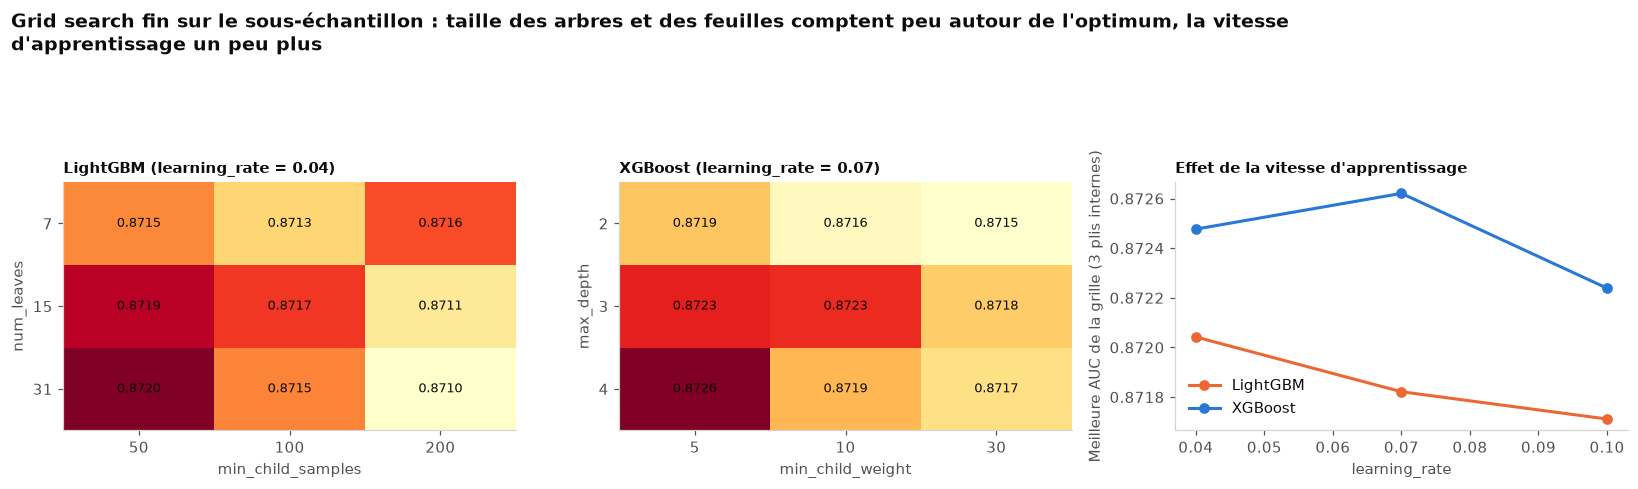

In [11]:
# ---------- grid search fin : vitesse d'apprentissage × taille des arbres × taille minimale des feuilles ----------
def around(values, best):
    i = values.index(best); lo = min(max(i - 1, 0), len(values) - 3)
    return values[lo:lo + 3]


LR_GRID = [.04, .07, .1]
for kind in ('lgbm', 'xgb'):
    k1, k2 = KEYS[kind]
    g1, g2 = around(sorted(SPACE_G[kind][k1]), BEST[kind][k1]), around(sorted(SPACE_G[kind][k2]), BEST[kind][k2])
    rows = []
    with timed(f'{LIBNAME[kind]} : grid search fin'):
        for lr in LR_GRID:
            for v1 in g1:
                for v2 in g2:
                    p = {**BEST[kind], **FIXED_G[kind], 'learning_rate': lr, k1: v1, k2: v2}
                    a, it, sd = inner_es(kind, p, patience=40, max_n=2000)
                    rows.append({'learning_rate': lr, k1: v1, k2: v2, 'auc_3plis': a, 'écart-type': sd, 'arbres': it})
    GRID[kind] = pd.DataFrame(rows).sort_values('auc_3plis', ascending=False).reset_index(drop=True)
    b = GRID[kind].loc[0]
    BEST[kind] = {**BEST[kind], k1: int(b[k1]), k2: int(b[k2])}
    BEST[kind]['learning_rate'] = float(b['learning_rate'])
    print(LIBNAME[kind], ': grid search fin')
    display(GRID[kind].head(5).style.format({'auc_3plis': '{:.4f}', 'écart-type': '{:.4f}', 'arbres': '{:.0f}', 'learning_rate': '{:.2f}'}))
md(' · '.join(f"**{LIBNAME[k]}** : meilleur point de la grille `learning_rate` = {BEST[k]['learning_rate']}, `{KEYS[k][0]}` = {BEST[k][KEYS[k][0]]}, `{KEYS[k][1]}` = {BEST[k][KEYS[k][1]]} (AUC {a4(GRID[k].loc[0, 'auc_3plis'])}, soit {'+' if GRID[k].loc[0, 'auc_3plis'] >= SEARCH[k].loc[0, 'auc_3plis'] else '−'}{fr(abs(GRID[k].loc[0, 'auc_3plis'] - SEARCH[k].loc[0, 'auc_3plis']), 4)} par rapport au random search ; écart-type entre plis internes {a4(GRID[k].loc[0, 'écart-type'])})" for k in GRID))

fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, kind in zip(axs[:2], ('lgbm', 'xgb')):
    k1, k2 = KEYS[kind]; G = GRID[kind]; lr_b = BEST[kind]['learning_rate']
    pv = G[G['learning_rate'] == lr_b].pivot_table(index=k1, columns=k2, values='auc_3plis')
    im = ax.imshow(pv.values, cmap='YlOrRd', aspect='auto')
    ax.set_xticks(range(pv.shape[1])); ax.set_xticklabels(pv.columns); ax.set_yticks(range(pv.shape[0])); ax.set_yticklabels(pv.index)
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            ax.text(j, i, f'{pv.values[i, j]:.4f}', ha='center', va='center', fontsize=8.5)
    ax.set_xlabel(k2); ax.set_ylabel(k1); ax.set_title(f'{LIBNAME[kind]} (learning_rate = {lr_b})', fontsize=10, loc='left')
ax = axs[2]
for kind, col in (('lgbm', c.ACCENT), ('xgb', c.BLUE)):
    s = GRID[kind].groupby('learning_rate')['auc_3plis'].max()
    ax.plot(s.index, s.values, marker='o', color=col, lw=2, label=LIBNAME[kind])
ax.set_xlabel('learning_rate'); ax.set_ylabel('Meilleure AUC de la grille (3 plis internes)'); ax.legend(frameon=False)
ax.set_title('Effet de la vitesse d\'apprentissage', fontsize=10, loc='left')
done(fig, '04_gbm_grille_fine', 'Grid search fin sur le sous-échantillon : taille des arbres et des feuilles comptent peu autour de l\'optimum, la vitesse d\'apprentissage un peu plus')

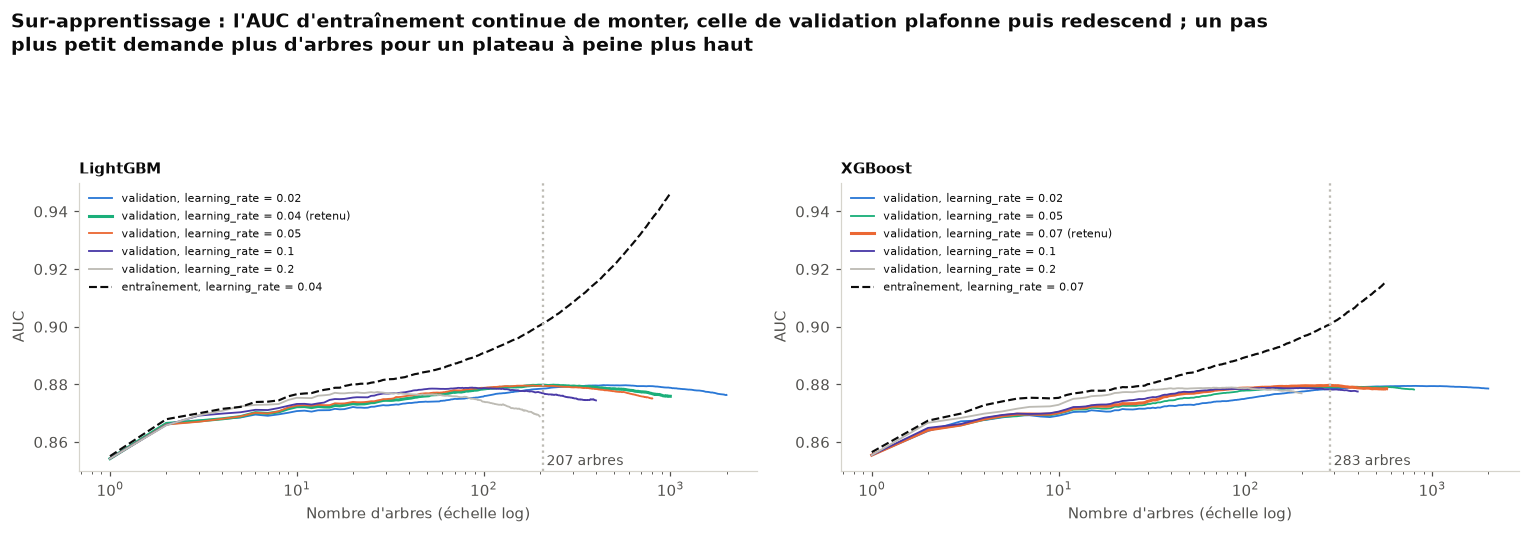

**LightGBM** : à `learning_rate` = 0.04, le sommet de la courbe de validation est atteint à **207 arbres** (AUC pli 0 : 0,8797 ; AUC d'entraînement au même point : 0,9010) · **XGBoost** : à `learning_rate` = 0.07, le sommet de la courbe de validation est atteint à **283 arbres** (AUC pli 0 : 0,8797 ; AUC d'entraînement au même point : 0,9008). Ces nombres d'arbres sont **fixés** pour la validation croisée.

In [12]:
# ---------- nombre d'arbres et sur-apprentissage : AUC d'entraînement et de validation au fil des itérations (pli 0) ----------
tr0, va0 = fold != 0, fold == 0
A0_tr, A0_va, y0_tr, y0_va = A_tr[tr0], A_tr[va0], yv[tr0], yv[va0]
tr_s = np.random.RandomState(c.SEED).choice(np.where(tr0)[0], 30_000, replace=False)       # clients d'entraînement servant à mesurer l'AUC « train »
A_trs, y_trs = A_tr[tr_s], yv[tr_s]


def final_params(kind):
    p = dict(BEST[kind])
    if kind == 'lgbm':
        p['subsample_freq'] = 1
    return p


def iter_curves(kind, lr):
    p = {**final_params(kind), 'learning_rate': lr}; n = int(CURVE_BUDGET / lr)
    if kind == 'lgbm':
        m = make_model('lgbm', n_estimators=n, metric='auc', **p)
        m.fit(A0_tr, y0_tr, eval_set=[(A0_va, y0_va), (A_trs, y_trs)], eval_names=['valid', 'train'])
        r = m.evals_result_
        return np.array(r['valid']['auc']), np.array(r['train']['auc'])
    m = make_model('xgb', n_estimators=n, eval_metric='auc', **p)
    m.fit(A0_tr, y0_tr, eval_set=[(A_trs, y_trs), (A0_va, y0_va)], verbose=False)
    r = m.evals_result()
    return np.array(r['validation_1']['auc']), np.array(r['validation_0']['auc'])


CURVES, N_STAR = {}, {}
for kind in ('lgbm', 'xgb'):
    lrs = sorted({.02, .05, .1, .2, BEST[kind]['learning_rate']})
    with timed(f'{LIBNAME[kind]} : courbes d\'itérations (pli 0)'):
        CURVES[kind] = {lr: iter_curves(kind, lr) for lr in lrs}
    v = pd.Series(CURVES[kind][BEST[kind]['learning_rate']][0])
    N_STAR[kind] = int(v.rolling(11, center=True, min_periods=1).mean().to_numpy().argmax()) + 1      # sommet de la courbe lissée

fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
cols_lr = [c.BLUE, c.GREEN, c.ACCENT, c.PURPLE, c.GREY]
for ax, kind in zip(axs, ('lgbm', 'xgb')):
    lr_b = BEST[kind]['learning_rate']
    for col, (lr, (v, t)) in zip(cols_lr, CURVES[kind].items()):
        ax.plot(np.arange(1, len(v) + 1), v, color=col, lw=2 if lr == lr_b else 1.2, label=f'validation, learning_rate = {lr}' + (' (retenu)' if lr == lr_b else ''))
    t = CURVES[kind][lr_b][1]
    ax.plot(np.arange(1, len(t) + 1), t, color=c.INK, lw=1.4, ls='--', label=f'entraînement, learning_rate = {lr_b}')
    ax.axvline(N_STAR[kind], color=c.GREY, ls=':'); ax.text(N_STAR[kind], .852, f' {N_STAR[kind]} arbres', fontsize=9, color=c.INK2)
    ax.set_xscale('log'); ax.set_ylim(.85, .95); ax.set_xlabel('Nombre d\'arbres (échelle log)'); ax.set_ylabel('AUC')
    ax.set_title(LIBNAME[kind], fontsize=10, loc='left'); ax.legend(frameon=False, fontsize=7.5, loc='upper left')
done(fig, '04_courbes_iterations', 'Sur-apprentissage : l\'AUC d\'entraînement continue de monter, celle de validation plafonne puis redescend ; un pas plus petit demande plus d\'arbres pour un plateau à peine plus haut')
md(' · '.join(f"**{LIBNAME[k]}** : à `learning_rate` = {BEST[k]['learning_rate']}, le sommet de la courbe de validation est atteint à **{N_STAR[k]} arbres** (AUC pli 0 : {a4(max(CURVES[k][BEST[k]['learning_rate']][0]))} ; AUC d'entraînement au même point : {a4(CURVES[k][BEST[k]['learning_rate']][1][N_STAR[k] - 1])})" for k in CURVES) + '. Ces nombres d\'arbres sont **fixés** pour la validation croisée.')

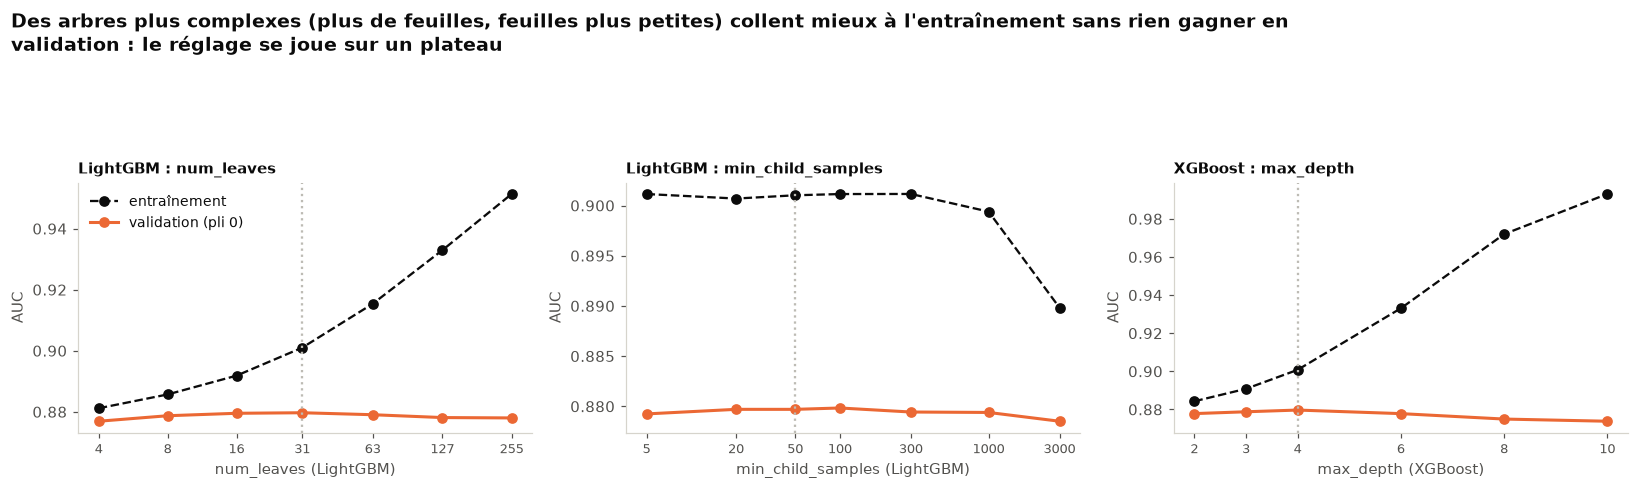

**Lecture** : LightGBM `num_leaves` : AUC de validation de 0,8769 à 0,8797 (maximum à 31), AUC d'entraînement de 0,8812 à 0,9514 ; LightGBM `min_child_samples` : AUC de validation de 0,8785 à 0,8798 (maximum à 100), AUC d'entraînement de 0,8898 à 0,9012 ; XGBoost `max_depth` : AUC de validation de 0,8738 à 0,8797 (maximum à 4), AUC d'entraînement de 0,8843 à 0,9931. L'écart entre entraînement et validation mesure le sur-apprentissage ; le trait pointillé gris marque la valeur retenue par la recherche.

In [13]:
# ---------- courbes de validation sur les paramètres de complexité (pli 0, nombre d'arbres fixé) ----------
def param_curve(kind, name, values):
    rows = []
    for v in values:
        p = {**final_params(kind), 'learning_rate': BEST[kind]['learning_rate'], 'n_estimators': N_STAR[kind], name: v}
        m = make_model(kind, **p).fit(A0_tr, y0_tr)
        rows.append({name: v, 'validation': roc_auc_score(y0_va, m.predict_proba(A0_va)[:, 1]), 'entraînement': roc_auc_score(y_trs, m.predict_proba(A_trs)[:, 1])})
    return pd.DataFrame(rows).set_index(name)


with timed('Courbes de validation des paramètres (pli 0)'):
    PC = {('lgbm', 'num_leaves'): param_curve('lgbm', 'num_leaves', [4, 8, 16, 31, 63, 127, 255]),
          ('lgbm', 'min_child_samples'): param_curve('lgbm', 'min_child_samples', [5, 20, 50, 100, 300, 1000, 3000]),
          ('xgb', 'max_depth'): param_curve('xgb', 'max_depth', [2, 3, 4, 6, 8, 10])}
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, ((kind, name), d) in zip(axs, PC.items()):
    ax.plot(d.index, d['entraînement'], color=c.INK, ls='--', marker='o', label='entraînement')
    ax.plot(d.index, d['validation'], color=c.ACCENT, marker='o', lw=2, label='validation (pli 0)')
    ax.axvline(BEST[kind][name], color=c.GREY, ls=':'); ax.set_xlabel(f'{name} ({LIBNAME[kind]})'); ax.set_ylabel('AUC')
    if name != 'max_depth': ax.set_xscale('log')
    ax.set_xticks(d.index); ax.set_xticklabels(d.index, fontsize=8.5); ax.minorticks_off()
    ax.set_title(f'{LIBNAME[kind]} : {name}', fontsize=10, loc='left')
axs[0].legend(frameon=False, fontsize=9)
done(fig, '04_courbes_parametres', 'Des arbres plus complexes (plus de feuilles, feuilles plus petites) collent mieux à l\'entraînement sans rien gagner en validation : le réglage se joue sur un plateau')
pc_txt = ' ; '.join(f"{LIBNAME[k]} `{n}` : AUC de validation de {a4(d['validation'].min())} à {a4(d['validation'].max())} (maximum à {d['validation'].idxmax()}), AUC d'entraînement de {a4(d['entraînement'].min())} à {a4(d['entraînement'].max())}" for (k, n), d in PC.items())
md(f'**Lecture** : {pc_txt}. L\'écart entre entraînement et validation mesure le sur-apprentissage ; le trait pointillé gris marque la valeur retenue par la recherche.')

In [14]:
# ---------- validation croisée à 5 plis des modèles réglés ----------
TUNED = {k: {**final_params(k), 'n_estimators': N_STAR[k]} for k in ('lgbm', 'xgb')}
with timed('XGBoost : modèle réglé (CV 5 plis)'):
    xgb_tun = run_cv('xgb_tuned', 'xgb', TUNED['xgb'], keep_fold0=True)
with timed('LightGBM : modèle réglé (CV 5 plis)'):
    lgb_tun = run_cv('lgbm_tuned', 'lgbm', TUNED['lgbm'], keep_fold0=True)
d_g = show_rows(['xgb_default', 'xgb_tuned', 'lgbm_default', 'lgbm_tuned'])
md(f'''Réglage : XGBoost passe de **{a4(xgb_def['rep']['auc'])}** à **{a4(xgb_tun['rep']['auc'])}** ({sg(xgb_tun['rep']['auc'] - xgb_def['rep']['auc'])} ; log-loss {a4(xgb_def['rep']['logloss'])} → {a4(xgb_tun['rep']['logloss'])}), LightGBM de **{a4(lgb_def['rep']['auc'])}** à **{a4(lgb_tun['rep']['auc'])}** ({sg(lgb_tun['rep']['auc'] - lgb_def['rep']['auc'])} ; log-loss {a4(lgb_def['rep']['logloss'])} → {a4(lgb_tun['rep']['logloss'])}). Le réglage compte donc beaucoup pour XGBoost (ses valeurs par défaut, `learning_rate` 0,3 et profondeur 6, sur-apprennent) et peu pour LightGBM, dont les valeurs par défaut sont déjà proches de l'optimum. Écart-type entre plis : {a4(xgb_tun['rep']['auc_fold_std'])} (XGBoost) et {a4(lgb_tun['rep']['auc_fold_std'])} (LightGBM) : la stabilité est bonne.
''')

,AUC,moy. plis,écart-type plis,log-loss,lift top 10 %,score moyen / taux,pente calibr.,s par pli
modèle,,,,,,,,
xgb_default,0.8662,0.8662,0.0029,0.1993,4.96,0.98,0.81,1.9
xgb_tuned,0.8779,0.8780,0.0026,0.1899,5.24,1.00,1.00,3.1
lgbm_default,0.8764,0.8765,0.0018,0.1909,5.22,1.00,0.98,1.1
lgbm_tuned,0.8785,0.8786,0.0022,0.1897,5.26,1.00,1.01,2.2


Réglage : XGBoost passe de **0,8662** à **0,8779** (+0,0117 ; log-loss 0,1993 → 0,1899), LightGBM de **0,8764** à **0,8785** (+0,0021 ; log-loss 0,1909 → 0,1897). Le réglage compte donc beaucoup pour XGBoost (ses valeurs par défaut, `learning_rate` 0,3 et profondeur 6, sur-apprennent) et peu pour LightGBM, dont les valeurs par défaut sont déjà proches de l'optimum. Écart-type entre plis : 0,0026 (XGBoost) et 0,0022 (LightGBM) : la stabilité est bonne.


### Gestion du déséquilibre (taux de rachat de 7,7 %)

Le rachat est rare : on pourrait vouloir « rééquilibrer » en donnant plus de poids aux clients qui rachètent (`scale_pos_weight` pour XGBoost et LightGBM, `class_weight` pour la forêt). Test : poids = 1 (rien), racine du rapport non-rachat / rachat (≈ 3,4), puis le rapport lui-même (≈ 12). Deux métriques racontent des choses différentes : l'**AUC** (le classement) et le **log-loss** avec la **calibration** (la justesse du niveau de probabilité).

,modèle,poids des rachats,AUC,log-loss,lift top 10 %,score moyen / taux réel,pente de calibration
0,LightGBM,aucun (poids 1),0.8785,0.1897,5.26,1.00,1.01
1,LightGBM,racine du rapport,0.8781,0.2378,5.26,2.14,1.01
2,LightGBM,rapport complet,0.8776,0.4176,5.25,3.86,1.01
3,XGBoost,aucun (poids 1),0.8779,0.1899,5.24,1.00,1.00
4,XGBoost,racine du rapport,0.8781,0.2385,5.26,2.16,1.01
5,XGBoost,rapport complet,0.8778,0.4224,5.22,3.92,1.01
6,Forêt aléatoire,aucun (poids 1),0.8754,0.1916,5.23,1.00,1.04
7,Forêt aléatoire,rapport complet (équilibré),0.8758,0.3536,5.24,3.36,0.98


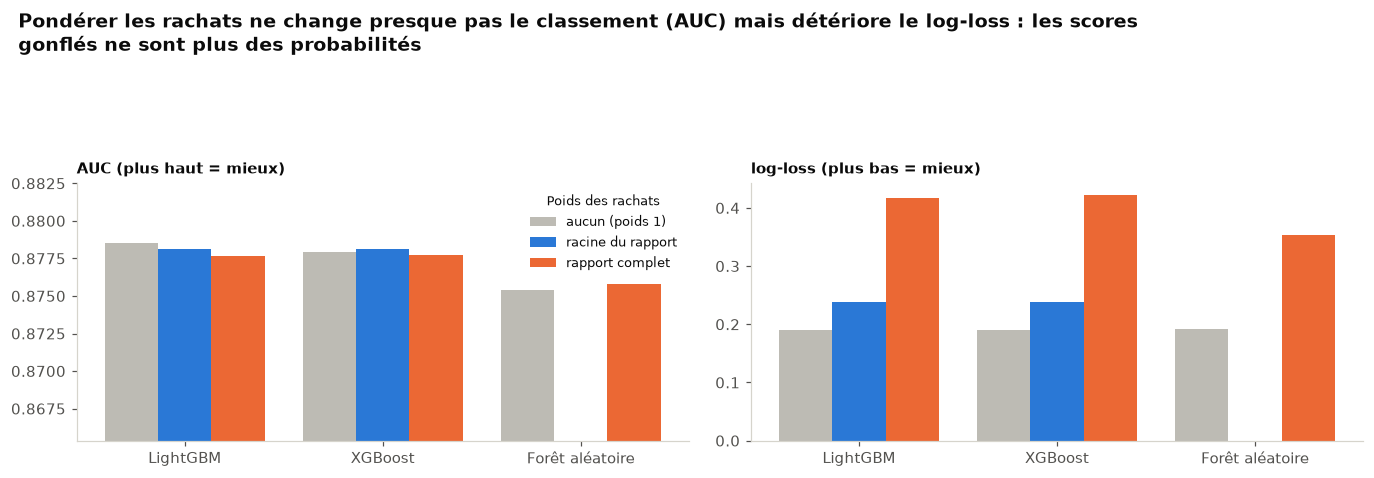

In [15]:
ratio = (1 - BASE_RATE) / BASE_RATE
IMB = {}
with timed('Déséquilibre : scale_pos_weight (CV 5 plis)'):
    for kind, tun in (('lgbm', lgb_tun), ('xgb', xgb_tun)):
        for lab, w in (('racine', np.sqrt(ratio)), ('rapport complet', ratio)):
            nm = f'{kind}_tuned_spw' if lab == 'rapport complet' else f'{kind}_tuned_spwsqrt'
            r = run_cv(nm, kind, {**TUNED[kind], 'scale_pos_weight': float(w)}, store=(lab == 'rapport complet'))
            IMB[nm] = r
imb = []
for kind, tun in (('lgbm', lgb_tun), ('xgb', xgb_tun)):
    for lab, nm in (('aucun (poids 1)', f'{kind}_tuned'), ('racine du rapport', f'{kind}_tuned_spwsqrt'), ('rapport complet', f'{kind}_tuned_spw')):
        r = RESULTS[nm] if nm in RESULTS else IMB[nm]
        cs = calib_stats(r['oof'].to_numpy(), yv)
        imb.append({'modèle': LIBNAME[kind], 'poids des rachats': lab, 'AUC': r['rep']['auc'], 'log-loss': r['rep']['logloss'],
                    'lift top 10 %': r['rep']['lift_top10'], 'score moyen / taux réel': cs['mean_ratio'], 'pente de calibration': cs['slope']})
for nm, lab in (('rf_tuned', 'aucun (poids 1)'), ('rf_tuned_cw', 'rapport complet (équilibré)')):
    r = RESULTS[nm]; cs = calib_stats(r['oof'].to_numpy(), yv)
    imb.append({'modèle': 'Forêt aléatoire', 'poids des rachats': lab, 'AUC': r['rep']['auc'], 'log-loss': r['rep']['logloss'],
                'lift top 10 %': r['rep']['lift_top10'], 'score moyen / taux réel': cs['mean_ratio'], 'pente de calibration': cs['slope']})
imb = pd.DataFrame(imb)
display(imb.style.format({'AUC': '{:.4f}', 'log-loss': '{:.4f}', 'lift top 10 %': '{:.2f}', 'score moyen / taux réel': '{:.2f}', 'pente de calibration': '{:.2f}'}))
c.save_result('04_desequilibre', imb.set_index(['modèle', 'poids des rachats']))

fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.3))
labs = list(dict.fromkeys(imb['poids des rachats'])); mods = list(dict.fromkeys(imb['modèle']))
for ax, met in zip(axs, ('AUC', 'log-loss')):
    w = .27
    for j, lab in enumerate(['aucun (poids 1)', 'racine du rapport', 'rapport complet']):
        vals = []
        for mo in mods:
            s = imb[(imb['modèle'] == mo) & (imb['poids des rachats'].isin([lab] + (['rapport complet (équilibré)'] if lab == 'rapport complet' else [])))]
            vals.append(s[met].iloc[0] if len(s) else np.nan)
        ax.bar(np.arange(len(mods)) + (j - 1) * w, vals, w, color=[c.GREY, c.BLUE, c.ACCENT][j], label=lab)
    ax.set_xticks(range(len(mods))); ax.set_xticklabels(mods); ax.set_title(met + (' (plus haut = mieux)' if met == 'AUC' else ' (plus bas = mieux)'), fontsize=10, loc='left')
    if met == 'AUC': ax.set_ylim(imb['AUC'].min() - .01, imb['AUC'].max() + .004)
axs[0].legend(frameon=False, fontsize=8.5, title='Poids des rachats', title_fontsize=8.5)
done(fig, '04_desequilibre', 'Pondérer les rachats ne change presque pas le classement (AUC) mais détériore le log-loss : les scores gonflés ne sont plus des probabilités')

## 5. Quelles variables comptent vraiment ? Ablation par famille

On repart du LightGBM réglé et on **retire une famille de variables à la fois** (les 10 familles de `results/02_feature_dictionary.csv`), puis on mesure la **perte d'AUC** sur les 5 plis (et, séparément, celle des deux variables `share_weekend` et `share_saturday`). Pour que la comparaison soit propre, le modèle complet est recalculé dans les mêmes conditions (vitesse d'apprentissage 0,1 et nombre d'arbres ajusté pour aller plus vite). La perte est calculée **pli par pli** (mêmes clients), ce qui donne une incertitude honnête. Une famille redondante avec une autre (récence et fréquence se recouvrent) coûte peu quand on la retire : cela ne veut pas dire qu'elle est inutile seule, mais qu'elle n'est pas **indispensable**.

On teste en plus un retrait ciblé : les **variables de profil d'identité** (civilité, domaine et type d'e-mail, présence d'un e-mail, département, département manquant). Question : utiles ou bruit ? Elles posent un **risque de proxy** : le domaine d'e-mail (fournisseur d'accès, webmail) et le département renseignent indirectement sur l'âge, le niveau de revenu et le territoire ; la civilité est un attribut protégé. Si leur retrait ne coûte rien, mieux vaut s'en passer (RGPD : minimisation, risque de discrimination indirecte).

*Lien avec le cours* : sélection de variables par les arbres et le boosting (slides 85-88), comparaison de versions (slide 73).

,variables retirées,auc,perte_auc,perte_moy_plis,perte_ecart_type_plis,logloss,lift_top10,precision_top10
retrait,,,,,,,,
Saisonnalité,9,0.8708,-0.0064,-0.0064,0.0007,0.1947,5.07,0.392
Parts de week-end et de samedi (2 variables),2,0.8718,-0.0054,-0.0054,0.0012,0.1941,5.06,0.391
Rythme et tendance,15,0.8769,-0.0004,-0.0003,0.0003,0.1908,5.21,0.402
Récence,4,0.8769,-0.0003,-0.0003,0.0003,0.1909,5.21,0.402
"Profil d'identité (e-mail, département, civilité)",6,0.8770,-0.0002,-0.0002,0.0004,0.1907,5.23,0.404
Fréquence,9,0.8772,-0.0000,-0.0000,0.0006,0.1907,5.25,0.405
Magasins,6,0.8772,+0.0000,+0.0000,0.0005,0.1904,5.21,0.402
Profil client,11,0.8773,+0.0001,+0.0001,0.0004,0.1904,5.26,0.406
Segment de prix,2,0.8774,+0.0002,+0.0002,0.0003,0.1903,5.23,0.404


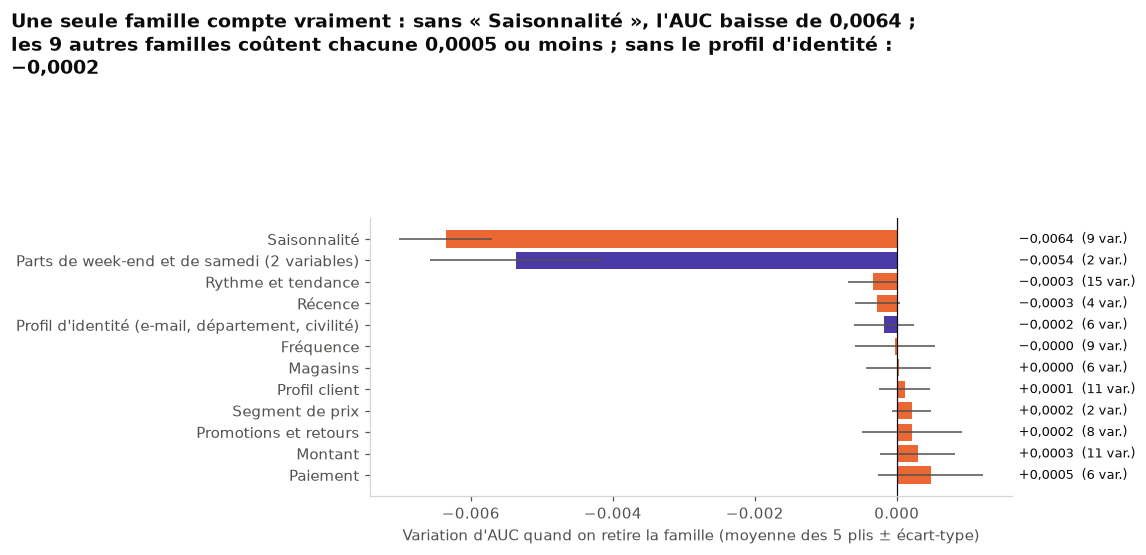

**Lecture.** « Saisonnalité » est la seule famille dont le retrait fait perdre de l'AUC de façon nette (−0,0064, soit 10 fois l'écart-type de la perte entre plis) ; les autres familles sont **redondantes** entre elles (récence, fréquence, montant et rythme se recouvrent) : les retirer une à une ne coûte presque rien. Les deux seules variables `share_weekend` et `share_saturday` suffisent à expliquer l'essentiel de cette perte : leur retrait coûte −0,0054 d'AUC. À interpréter avec prudence (section 7) : la cible est un mois unique, août 2020. Retirer le **profil d'identité** coûte −0,0002 d'AUC : négligeable devant le bruit entre plis.


In [16]:
PROFILE_VARS = ['civility', 'has_email', 'email_domain', 'email_type', 'dept', 'dept_missing']
cols_of = lambda ks: [e for k in ks for e in MAP[k]]
PROF_KEY, WE_KEY = 'Profil d\'identité (e-mail, département, civilité)', 'Parts de week-end et de samedi (2 variables)'
SPECIAL = {PROF_KEY: PROFILE_VARS, WE_KEY: ['share_weekend', 'share_saturday']}
FAST_LR = .1
p_abl = {**TUNED['lgbm'], 'learning_rate': FAST_LR, 'n_estimators': max(100, int(round(TUNED['lgbm']['n_estimators'] * TUNED['lgbm']['learning_rate'] / FAST_LR)))}
with timed('Ablation par famille (LightGBM, CV 5 plis × 12)'):
    ref = run_cv('abl_complet', 'lgbm', p_abl, store=False)
    abl = []
    for g in GROUPS + list(SPECIAL):
        removed = SPECIAL[g] if g in SPECIAL else [k for k in base_cols if dico.loc[k, 'group'] == g]
        r = run_cv('abl', 'lgbm', p_abl, cols=cols_of([k for k in base_cols if k not in removed]), store=False)
        dpf = np.array(r['per_fold']) - np.array(ref['per_fold'])
        abl.append({'retrait': g, 'variables retirées': len(removed), 'auc': r['rep']['auc'], 'perte_auc': r['rep']['auc'] - ref['rep']['auc'],
                    'perte_moy_plis': dpf.mean(), 'perte_ecart_type_plis': dpf.std(), 'logloss': r['rep']['logloss'],
                    'lift_top10': r['rep']['lift_top10'], 'precision_top10': r['rep']['precision_top10']})
abl = pd.DataFrame(abl).set_index('retrait').sort_values('perte_auc')
c.save_result('04_ablation_familles', abl)
display(abl.style.format({'auc': '{:.4f}', 'perte_auc': '{:+.4f}', 'perte_moy_plis': '{:+.4f}', 'perte_ecart_type_plis': '{:.4f}', 'logloss': '{:.4f}', 'lift_top10': '{:.2f}', 'precision_top10': '{:.3f}'}))

fig, ax = plt.subplots(figsize=(10.5, 5))
d = abl.iloc[::-1]
colors = [c.PURPLE if i in SPECIAL else c.ACCENT for i in d.index]
ax.barh(d.index, d['perte_moy_plis'], xerr=d['perte_ecart_type_plis'], color=colors, error_kw=dict(ecolor=c.INK2, lw=1))
ax.axvline(0, color=c.INK, lw=.8); ax.set_xlabel('Variation d\'AUC quand on retire la famille (moyenne des 5 plis ± écart-type)')
for i, (v, n) in enumerate(zip(d['perte_moy_plis'], d['variables retirées'])):
    ax.text(1.01, i, f'{sg(v)}  ({n} var.)', transform=ax.get_yaxis_transform(), va='center', ha='left', fontsize=8.5)
fam_loss = abl.loc[GROUPS, 'perte_moy_plis'].sort_values()
worst = fam_loss.index[0]; n_flat = int((fam_loss.iloc[1:].abs() <= .0005).sum()); prof = abl.loc[PROF_KEY]; wk = abl.loc[WE_KEY]
done(fig, '04_ablation_familles', f"Une seule famille compte vraiment : sans « {worst} », l'AUC baisse de {fr(-fam_loss.iloc[0], 4)} ; {'les ' + str(n_flat) + ' autres familles coûtent chacune' if n_flat == len(GROUPS) - 1 else str(n_flat) + ' des ' + str(len(GROUPS) - 1) + ' autres familles coûtent'} 0,0005 ou moins ; sans le profil d'identité : {sg(prof['perte_moy_plis'])}")
md(f'''**Lecture.** « {worst} » est la seule famille dont le retrait fait perdre de l'AUC de façon nette ({sg(fam_loss.iloc[0])}, soit {fr(abs(fam_loss.iloc[0]) / abl.loc[worst, 'perte_ecart_type_plis'], 0)} fois l'écart-type de la perte entre plis) ; les autres familles sont **redondantes** entre elles (récence, fréquence, montant et rythme se recouvrent) : les retirer une à une ne coûte presque rien. Les deux seules variables `share_weekend` et `share_saturday` suffisent à expliquer l'essentiel de cette perte : leur retrait coûte {sg(wk['perte_moy_plis'])} d'AUC. À interpréter avec prudence (section 7) : la cible est un mois unique, août 2020. Retirer le **profil d'identité** coûte {sg(prof['perte_moy_plis'])} d'AUC : négligeable devant le bruit entre plis.
''')

In [17]:
# Modèle sans variables de profil d'identité, avec les hyperparamètres réglés (version candidate, comparable à lgbm_tuned)
cols_noprof = cols_of([k for k in base_cols if k not in PROFILE_VARS])
with timed('LightGBM sans profil d\'identité (CV 5 plis)'):
    lgb_np = run_cv('lgbm_no_profile', 'lgbm', TUNED['lgbm'], cols=cols_noprof)
dnp = np.array(lgb_np['per_fold']) - np.array(lgb_tun['per_fold'])
md(f'''**Avec ou sans profil d'identité** (hyperparamètres réglés, 5 plis) : AUC **{a4(lgb_tun['rep']['auc'])}** avec, **{a4(lgb_np['rep']['auc'])}** sans ({sg(lgb_np['rep']['auc'] - lgb_tun['rep']['auc'])} ; écart pli par pli {sg(dnp.mean())} ± {fr(dnp.std(), 4)}) ; lift top 10 % {fr(lgb_tun['rep']['lift_top10'], 2)} avec, {fr(lgb_np['rep']['lift_top10'], 2)} sans.
''')

**Avec ou sans profil d'identité** (hyperparamètres réglés, 5 plis) : AUC **0,8785** avec, **0,8783** sans (−0,0002 ; écart pli par pli −0,0002 ± 0,0002) ; lift top 10 % 5,26 avec, 5,23 sans.


## 6. Comparaison des versions

Toutes les versions sont évaluées de la même façon : les **mêmes 5 plis**, les prédictions **hors-échantillon**, et les métriques du brief : **AUC** (classement, sans seuil), **log-loss** (justesse des probabilités), **précision / rappel / lift dans le top 10 %** (la contrainte métier : au plus 10 % de la base ciblée). On y ajoute la **stabilité** (AUC pli par pli), le **temps d'entraînement** et l'**interprétabilité**, comme le demande la sélection finale du cours (slide 73) : le meilleur modèle n'est pas seulement celui qui a la plus haute AUC.

In [18]:
MAIN = ['rf_default', 'rf_tuned', 'rf_tuned_cw', 'xgb_default', 'xgb_tuned', 'xgb_tuned_spw', 'lgbm_default', 'lgbm_tuned', 'lgbm_tuned_spw', 'lgbm_no_profile']
FAMILY = {'rf': 'Forêt aléatoire', 'xgb': 'XGBoost', 'lgbm': 'LightGBM'}
INTERP = {'rf': 'Moyenne : importance des variables, pas de formule lisible',
          'xgb': 'Faible sans outil d\'explication : importances, dépendance partielle (SHAP au notebook 06)',
          'lgbm': 'Faible sans outil d\'explication : importances, dépendance partielle (SHAP au notebook 06)'}
CS = {n: calib_stats(RESULTS[n]['oof'].to_numpy(), yv) for n in MAIN}
REMARK = {
    'rf_default': 'Non réglée (scikit-learn par défaut) : feuilles d\'un client, probabilités tranchées, log-loss élevé',
    'rf_tuned': f"Réglée (random search sur {nf(SUB_N)} clients) : {N_TREES} arbres, feuilles plus grosses ; imputation médiane",
    'rf_tuned_cw': f"class_weight équilibré : score moyen = {fr(CS['rf_tuned_cw']['mean_ratio'], 1)} × le taux réel, classement quasi inchangé",
    'xgb_default': 'Non réglé (défauts : 100 arbres, profondeur 6, learning_rate 0,3)',
    'xgb_tuned': f"Réglé (random + grid fin, {N_STAR['xgb']} arbres par arrêt anticipé sur le pli 0)",
    'xgb_tuned_spw': f"scale_pos_weight = rapport complet : score moyen = {fr(CS['xgb_tuned_spw']['mean_ratio'], 1)} × le taux réel" if 'xgb_tuned_spw' in CS else '',
    'lgbm_default': 'Non réglé (défauts : 100 arbres, 31 feuilles, learning_rate 0,1)',
    'lgbm_tuned': f"Réglé (random + grid fin, {N_STAR['lgbm']} arbres par arrêt anticipé sur le pli 0)",
    'lgbm_tuned_spw': f"scale_pos_weight = rapport complet : score moyen = {fr(CS['lgbm_tuned_spw']['mean_ratio'], 1)} × le taux réel",
    'lgbm_no_profile': 'Réglé, sans civilité, e-mail ni département (risque de proxy d\'âge et de territoire)'}
rows = [{'model': 'recence_regle', 'family': 'Règle de référence', 'params': 'score = - jours depuis le dernier achat', **{k: rep_rec[k] for k in ('auc', 'auc_fold_mean', 'auc_fold_std', 'logloss', 'precision_top10', 'recall_top10', 'lift_top10')},
         'fit_seconds': 0.0, 'interpretability': 'Très élevée : une seule variable, une règle', 'remark': 'Repère à battre ; le log-loss n\'a pas de sens (ce n\'est pas une probabilité)'}]
for nm in MAIN:
    r = RESULTS[nm]
    rows.append({'model': nm, 'family': FAMILY[r['kind']], 'params': json.dumps(r['params'], default=str, ensure_ascii=False),
                 **{k: r['rep'][k] for k in ('auc', 'auc_fold_mean', 'auc_fold_std', 'logloss', 'precision_top10', 'recall_top10', 'lift_top10')},
                 'fit_seconds': r['fit_seconds'], 'interpretability': INTERP[r['kind']], 'remark': REMARK[nm]})
comp = pd.DataFrame(rows).set_index('model')
c.save_result('04_model_comparison', comp)
display(comp[['family', 'auc', 'auc_fold_mean', 'auc_fold_std', 'logloss', 'precision_top10', 'recall_top10', 'lift_top10', 'fit_seconds']].style.format(
    {'auc': '{:.4f}', 'auc_fold_mean': '{:.4f}', 'auc_fold_std': '{:.4f}', 'logloss': '{:.4f}', 'precision_top10': '{:.1%}', 'recall_top10': '{:.1%}', 'lift_top10': '{:.2f}', 'fit_seconds': '{:.1f}'}))

BEST_NAME = comp.drop('recence_regle')['auc'].idxmax()
srt = comp.drop('recence_regle').sort_values('auc', ascending=False)
second = srt.index[1]
dd = np.array(RESULTS[BEST_NAME]['per_fold']) - np.array(RESULTS[second]['per_fold'])
bn = comp.loc[BEST_NAME]
md(f'''**Lecture.** Meilleur modèle de ce notebook : **`{BEST_NAME}`** (AUC {a4(bn['auc'])}, top 10 % : précision {pc(bn['precision_top10'])}, rappel {pc(bn['recall_top10'])}, lift {fr(bn['lift_top10'], 2)}), contre {a4(rep_rec['auc'])} pour la récence seule (précision {pc(rep_rec['precision_top10'])}, rappel {pc(rep_rec['recall_top10'])}). Il devance `{second}` de {sg(dd.mean())} d'AUC en moyenne pli par pli (écart-type de la différence {fr(dd.std(), 4)}, positif dans {int((dd > 0).sum())} plis sur {c.N_FOLDS}). Ciblé sur 10 % de la base, il capte **{pc(bn['recall_top10'])}** des rachats, soit {fr(bn['recall_top10'] * 100 - rep_rec['recall_top10'] * 100, 1)} points de plus que la règle de récence. Les trois familles réglées sont séparées par peu de points d'AUC (forêt {a4(comp.loc['rf_tuned', 'auc'])}, XGBoost {a4(comp.loc['xgb_tuned', 'auc'])}, LightGBM {a4(comp.loc['lgbm_tuned', 'auc'])}) ; l'écart entre plis ({a4(comp.loc[BEST_NAME, 'auc_fold_std'])}) donne l'ordre de grandeur du bruit.
''')

,family,auc,auc_fold_mean,auc_fold_std,logloss,precision_top10,recall_top10,lift_top10,fit_seconds
model,,,,,,,,,
recence_regle,Règle de référence,0.8180,0.8180,0.0035,1.0672,23.5%,30.4%,3.04,0.0
rf_default,Forêt aléatoire,0.8628,0.8629,0.0021,0.2106,39.2%,50.7%,5.07,5.8
rf_tuned,Forêt aléatoire,0.8754,0.8754,0.0022,0.1916,40.4%,52.3%,5.23,19.7
rf_tuned_cw,Forêt aléatoire,0.8758,0.8758,0.0022,0.3536,40.5%,52.4%,5.24,18.2
xgb_default,XGBoost,0.8662,0.8662,0.0029,0.1993,38.3%,49.6%,4.96,1.9
xgb_tuned,XGBoost,0.8779,0.8780,0.0026,0.1899,40.5%,52.4%,5.24,3.1
xgb_tuned_spw,XGBoost,0.8778,0.8778,0.0025,0.4224,40.3%,52.2%,5.22,3.2
lgbm_default,LightGBM,0.8764,0.8765,0.0018,0.1909,40.3%,52.2%,5.22,1.1
lgbm_tuned,LightGBM,0.8785,0.8786,0.0022,0.1897,40.6%,52.6%,5.26,2.2


**Lecture.** Meilleur modèle de ce notebook : **`lgbm_tuned`** (AUC 0,8785, top 10 % : précision 40,6 %, rappel 52,6 %, lift 5,26), contre 0,8180 pour la récence seule (précision 23,5 %, rappel 30,4 %). Il devance `lgbm_no_profile` de +0,0002 d'AUC en moyenne pli par pli (écart-type de la différence 0,0002, positif dans 4 plis sur 5). Ciblé sur 10 % de la base, il capte **52,6 %** des rachats, soit 22,2 points de plus que la règle de récence. Les trois familles réglées sont séparées par peu de points d'AUC (forêt 0,8754, XGBoost 0,8779, LightGBM 0,8785) ; l'écart entre plis (0,0022) donne l'ordre de grandeur du bruit.


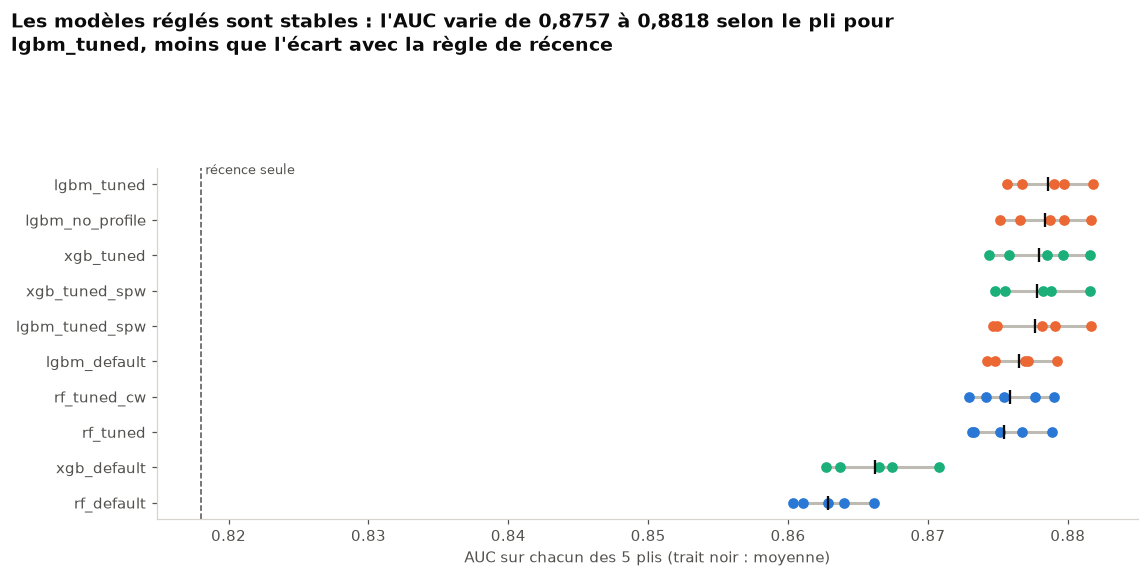

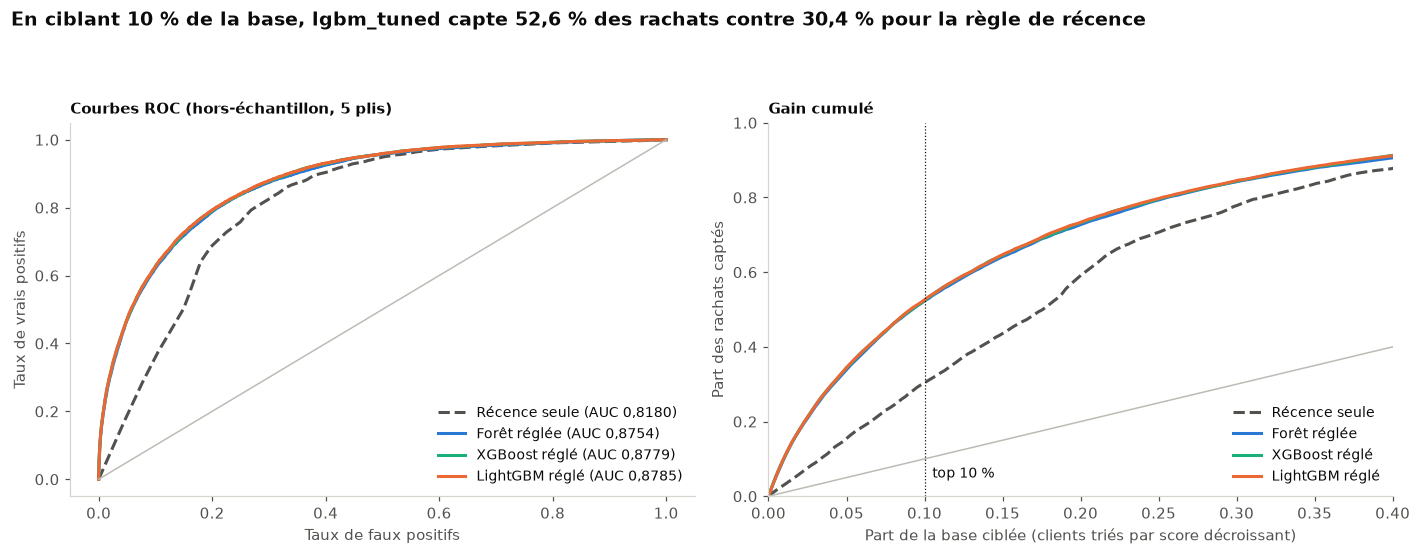

In [19]:
# ---- AUC pli par pli (stabilité) ----
order = srt.index[::-1]
fig, ax = plt.subplots(figsize=(10.5, 5.2))
for i, nm in enumerate(order):
    pf = RESULTS[nm]['per_fold']
    ax.plot([min(pf), max(pf)], [i, i], color=c.GREY, lw=2, zorder=1)
    ax.scatter(pf, [i] * len(pf), s=36, color={'rf': c.BLUE, 'xgb': c.GREEN, 'lgbm': c.ACCENT}[RESULTS[nm]['kind']], zorder=2)
    ax.scatter(np.mean(pf), i, s=90, marker='|', color=c.INK, zorder=3)
ax.axvline(rep_rec['auc'], color=c.INK2, ls='--', lw=1); ax.text(rep_rec['auc'], len(order) - .4, ' récence seule', fontsize=8.5, color=c.INK2, ha='left', va='top')
ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.set_xlabel('AUC sur chacun des 5 plis (trait noir : moyenne)')
done(fig, '04_auc_par_pli', f"Les modèles réglés sont stables : l'AUC varie de {a4(min(RESULTS[BEST_NAME]['per_fold']))} à {a4(max(RESULTS[BEST_NAME]['per_fold']))} selon le pli pour {BEST_NAME}, moins que l'écart avec la règle de récence")

# ---- ROC et gain cumulé ----
def gain_curve(score, n=400):
    o = np.argsort(-np.asarray(score), kind='stable'); cum = np.cumsum(yv[o]) / yv.sum(); idx = np.unique(np.linspace(0, len(o) - 1, n).astype(int))
    return (idx + 1) / len(o), cum[idx]


curves = [('Récence seule', score_rec.to_numpy(), c.INK2, '--'), ('Forêt réglée', RESULTS['rf_tuned']['oof'].to_numpy(), c.BLUE, '-'),
          ('XGBoost réglé', RESULTS['xgb_tuned']['oof'].to_numpy(), c.GREEN, '-'), ('LightGBM réglé', RESULTS['lgbm_tuned']['oof'].to_numpy(), c.ACCENT, '-')]
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for lab, s, col, ls in curves:
    fpr, tpr, _ = roc_curve(yv, s); axs[0].plot(fpr, tpr, color=col, ls=ls, lw=2, label=f'{lab} (AUC {a4(roc_auc_score(yv, s))})')
    gx, gy = gain_curve(s); axs[1].plot(gx, gy, color=col, ls=ls, lw=2, label=lab)
axs[0].plot([0, 1], [0, 1], color=c.GREY, lw=1); axs[0].set_xlabel('Taux de faux positifs'); axs[0].set_ylabel('Taux de vrais positifs'); axs[0].legend(frameon=False, fontsize=9, loc='lower right')
axs[0].set_title('Courbes ROC (hors-échantillon, 5 plis)', fontsize=10, loc='left')
axs[1].plot([0, 1], [0, 1], color=c.GREY, lw=1); axs[1].set_xlim(0, .4); axs[1].set_ylim(0, 1)
axs[1].axvline(c.TOP_FRAC, color=c.INK, lw=.8, ls=':'); axs[1].text(c.TOP_FRAC + .005, .05, 'top 10 %', fontsize=9)
axs[1].set_xlabel('Part de la base ciblée (clients triés par score décroissant)'); axs[1].set_ylabel('Part des rachats captés'); axs[1].legend(frameon=False, fontsize=9, loc='lower right')
axs[1].set_title('Gain cumulé', fontsize=10, loc='left')
done(fig, '04_roc_gain', f"En ciblant 10 % de la base, {BEST_NAME} capte {pc(bn['recall_top10'])} des rachats contre {pc(rep_rec['recall_top10'])} pour la règle de récence")

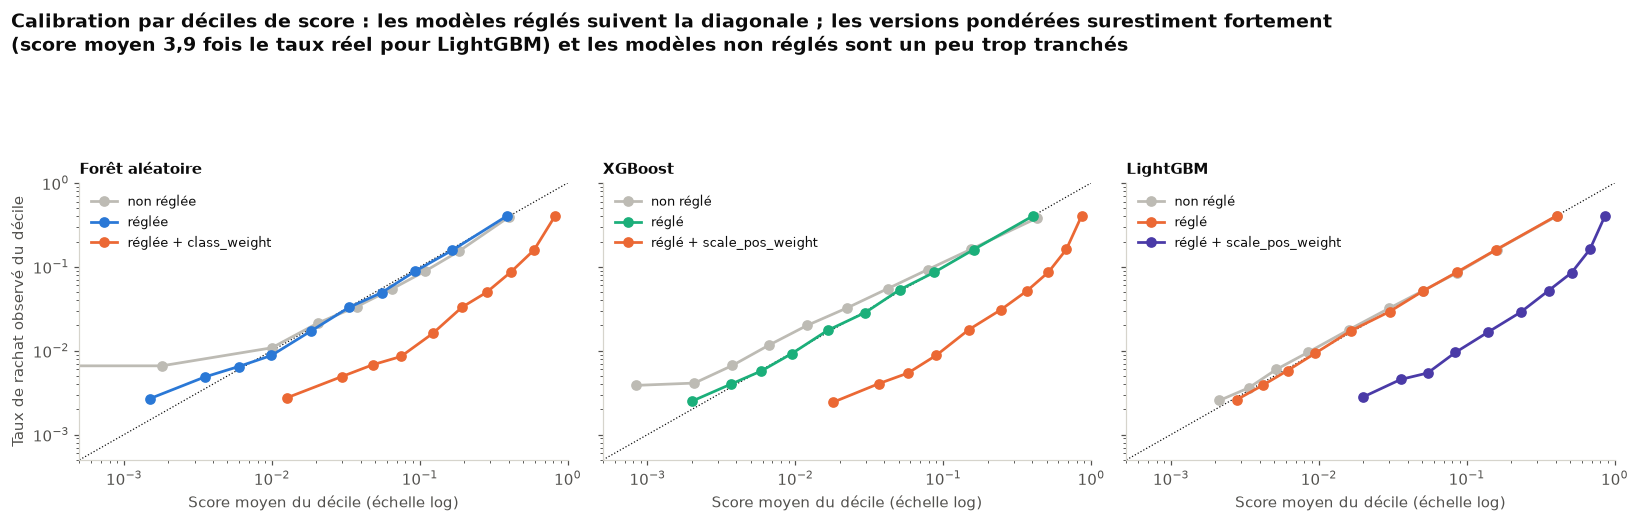

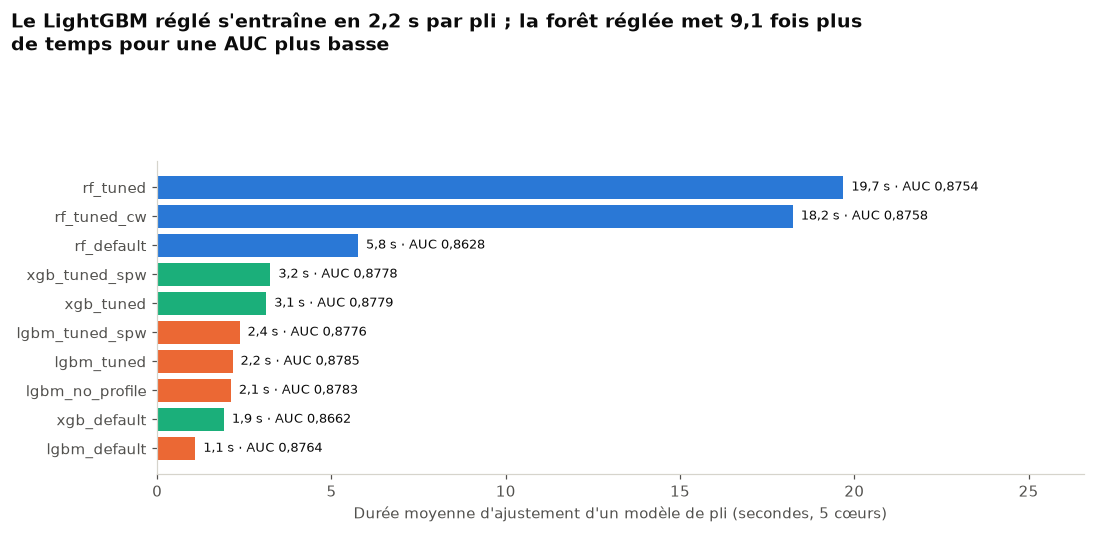

In [20]:
# ---- calibration ----
fig, axs = plt.subplots(1, 3, figsize=(15, 4.7), sharex=True, sharey=True)
panels = [('Forêt aléatoire', [('rf_default', c.GREY, 'non réglée'), ('rf_tuned', c.BLUE, 'réglée'), ('rf_tuned_cw', c.ACCENT, 'réglée + class_weight')]),
          ('XGBoost', [('xgb_default', c.GREY, 'non réglé'), ('xgb_tuned', c.GREEN, 'réglé'), ('xgb_tuned_spw', c.ACCENT, 'réglé + scale_pos_weight')]),
          ('LightGBM', [('lgbm_default', c.GREY, 'non réglé'), ('lgbm_tuned', c.ACCENT, 'réglé'), ('lgbm_tuned_spw', c.PURPLE, 'réglé + scale_pos_weight')])]
for ax, (ttl, lst) in zip(axs, panels):
    ax.plot([5e-4, 1], [5e-4, 1], color=c.INK, lw=.8, ls=':')
    for nm, col, lab in lst:
        g = calib_table(RESULTS[nm]['oof'].to_numpy(), yv)
        ax.plot(g['p'], g['y'].clip(lower=5e-4), marker='o', color=col, lw=1.8, label=lab)
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(5e-4, 1); ax.set_ylim(5e-4, 1)
    ax.set_xlabel('Score moyen du décile (échelle log)'); ax.set_title(ttl, fontsize=10, loc='left'); ax.legend(frameon=False, fontsize=8.5, loc='upper left')
axs[0].set_ylabel('Taux de rachat observé du décile')
done(fig, '04_calibration', f"Calibration par déciles de score : les modèles réglés suivent la diagonale ; les versions pondérées surestiment fortement (score moyen {fr(CS['lgbm_tuned_spw']['mean_ratio'], 1)} fois le taux réel pour LightGBM) et les modèles non réglés sont un peu trop tranchés")

# ---- temps d'entraînement ----
fig, ax = plt.subplots(figsize=(10, 4.8))
nm_ = list(comp.drop('recence_regle').sort_values('fit_seconds').index)
ax.barh(nm_, comp.loc[nm_, 'fit_seconds'], color=[{'Forêt aléatoire': c.BLUE, 'XGBoost': c.GREEN, 'LightGBM': c.ACCENT}[comp.loc[n, 'family']] for n in nm_])
for i, n in enumerate(nm_):
    ax.text(comp.loc[n, 'fit_seconds'], i, f"  {fr(comp.loc[n, 'fit_seconds'], 1)} s · AUC {fr(comp.loc[n, 'auc'], 4)}", va='center', fontsize=8.5)
ax.set_xlabel('Durée moyenne d\'ajustement d\'un modèle de pli (secondes, 5 cœurs)'); ax.margins(x=.35)
done(fig, '04_temps_entrainement', f"Le LightGBM réglé s'entraîne en {fr(comp.loc['lgbm_tuned', 'fit_seconds'], 1)} s par pli ; la forêt réglée met {fr(comp.loc['rf_tuned', 'fit_seconds'] / comp.loc['lgbm_tuned', 'fit_seconds'], 1)} fois plus de temps pour une AUC plus basse")

## 7. Importance des variables et lecture marketing

Trois angles, tous **descriptifs** (SHAP, qui attribue une contribution à chaque client, est réservé au notebook 06) :

- **Gain** (XGBoost, LightGBM) : la part de la réduction de la perte due aux découpes sur la variable, moyennée sur les 5 modèles de pli ; les colonnes one-hot d'une même variable sont additionnées. Défaut connu : quand des variables sont corrélées (n_tickets_30 et n_tickets_60), elles se partagent le gain.
- **Importance par permutation** : on **mélange** une variable (toutes les colonnes d'un même one-hot ensemble) sur un pli de validation (pli 0, 16 000 clients) et on mesure la baisse d'AUC du modèle LightGBM réglé ; 3 répétitions. Plus fiable que le gain pour dire « le modèle en a vraiment besoin », mais, là aussi, une variable corrélée à une autre est partiellement remplacée par elle.
- **Dépendance partielle** : pour les variables principales, le score moyen prédit quand on fait varier la variable seule, les autres restant telles qu'observées.

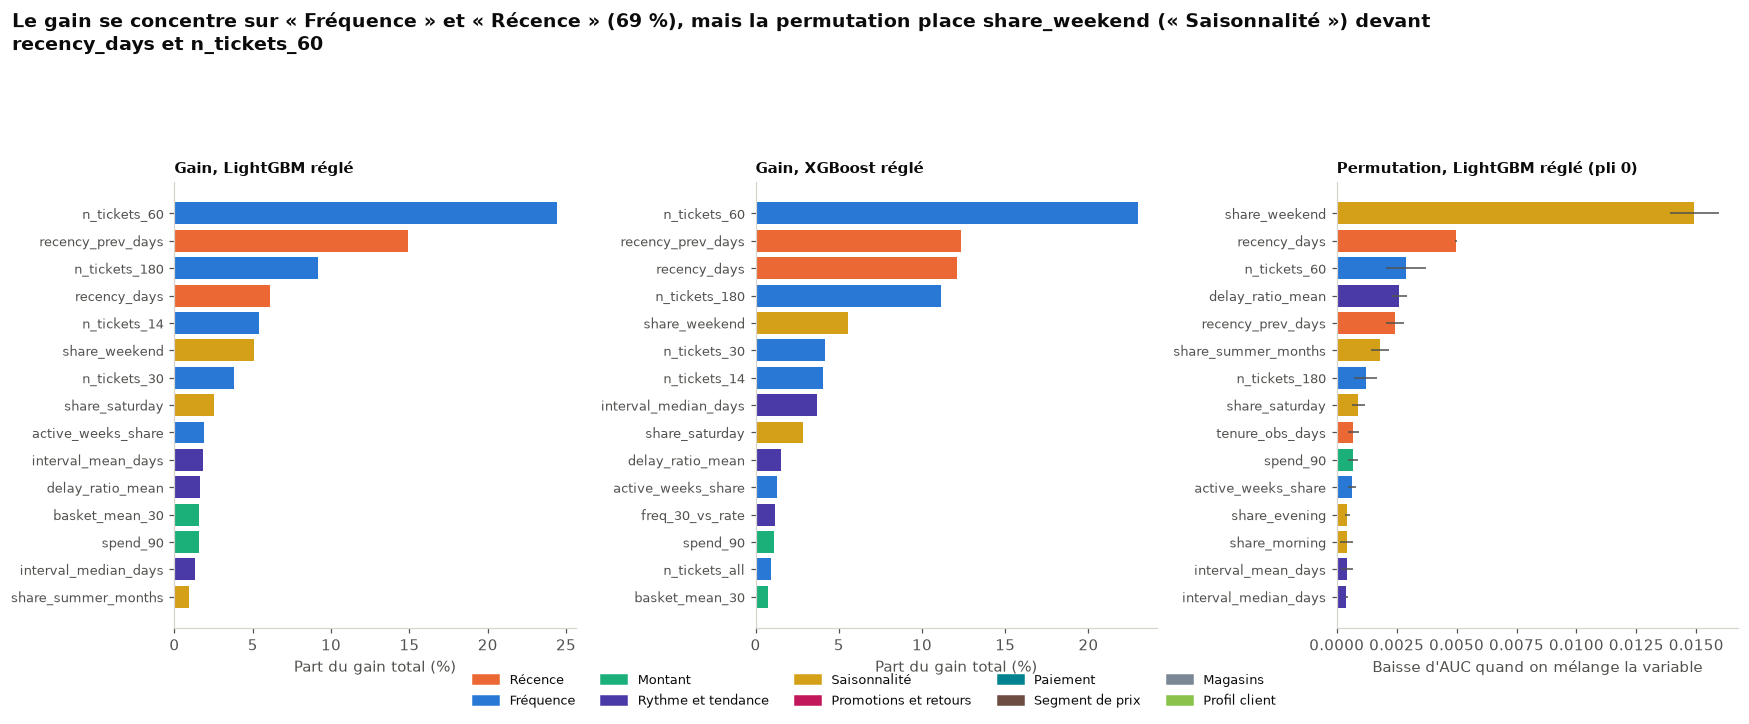

,LightGBM,XGBoost,Forêt
Fréquence,46.5 %,45.7 %,51.7 %
Récence,22.1 %,25.7 %,11.9 %
Saisonnalité,10.8 %,10.7 %,14.3 %
Rythme et tendance,9.0 %,9.7 %,10.4 %
Montant,6.6 %,4.6 %,5.7 %
Promotions et retours,2.5 %,1.5 %,3.0 %
Paiement,1.2 %,0.6 %,1.6 %
Magasins,0.7 %,0.6 %,0.8 %
Profil client,0.4 %,0.6 %,0.4 %
Segment de prix,0.2 %,0.2 %,0.2 %


In [21]:
GCOL = dict(zip(GROUPS, ['#eb6834', '#2a78d6', '#1baf7a', '#4a3aa7', '#d4a017', '#c2185b', '#00838f', '#6d4c41', '#7b8794', '#8bc34a']))
fam_of = lambda k: dico.loc[k, 'group']
gain = {kind: RESULTS[f'{kind}_tuned']['imp'].groupby(lambda e: OWNER[e]).sum().sort_values(ascending=False) for kind in ('lgbm', 'xgb')}
rf_imp = RESULTS['rf_tuned']['imp'].groupby(lambda e: OWNER[e]).sum().sort_values(ascending=False)

# importance par permutation (LightGBM réglé, pli 0)
m0 = RESULTS['lgbm_tuned']['model0']
rs = np.random.RandomState(c.SEED)
idx_v = rs.choice(len(A0_va), 16_000, replace=False)
Av, yvv = A0_va[idx_v].copy(), y0_va[idx_v]
auc_base = roc_auc_score(yvv, m0.predict_proba(Av)[:, 1])
perm = {}
with timed('Importance par permutation'):
    for k in base_cols:
        ci = [ENC_COLS.index(e) for e in MAP[k]]; orig = Av[:, ci].copy(); drops = []
        for _ in range(3):
            Av[:, ci] = orig[rs.permutation(len(Av))]
            drops.append(auc_base - roc_auc_score(yvv, m0.predict_proba(Av)[:, 1]))
        Av[:, ci] = orig
        perm[k] = (np.mean(drops), np.std(drops))
perm = pd.DataFrame(perm, index=['baisse_auc', 'ecart_type']).T.sort_values('baisse_auc', ascending=False)

fam_gain = pd.DataFrame({k: pd.Series({g: v[[x for x in v.index if fam_of(x) == g]].sum() for g in GROUPS}) for k, v in (('LightGBM', gain['lgbm']), ('XGBoost', gain['xgb']), ('Forêt', rf_imp))}).sort_values('LightGBM', ascending=False)
fig, axs = plt.subplots(1, 3, figsize=(16, 6.2))
for ax, (ttl, ser, xl) in zip(axs, [('Gain, LightGBM réglé', gain['lgbm'] * 100, 'Part du gain total (%)'), ('Gain, XGBoost réglé', gain['xgb'] * 100, 'Part du gain total (%)'),
                                    ('Permutation, LightGBM réglé (pli 0)', perm['baisse_auc'], 'Baisse d\'AUC quand on mélange la variable')]):
    top = ser.head(15)[::-1]
    ax.barh(top.index, top.values, color=[GCOL[fam_of(k)] for k in top.index])
    if 'Permutation' in ttl:
        ax.errorbar(top.values, range(len(top)), xerr=perm.loc[top.index, 'ecart_type'].values, fmt='none', ecolor=c.INK2, lw=1)
    ax.set_title(ttl, fontsize=10, loc='left'); ax.set_xlabel(xl); ax.tick_params(axis='y', labelsize=8.5)
handles = [plt.Rectangle((0, 0), 1, 1, color=GCOL[g]) for g in GROUPS]
fig.legend(handles, GROUPS, ncol=5, loc='lower center', frameon=False, fontsize=8.5, bbox_to_anchor=(.5, -.04))
top2 = fam_gain['LightGBM'].head(2)
done(fig, '04_importance_variables', f"Le gain se concentre sur « {top2.index[0]} » et « {top2.index[1]} » ({pc(top2.sum(), 0)}), mais la permutation place {perm.index[0]} (« {fam_of(perm.index[0])} ») devant {perm.index[1]} et {perm.index[2]}")

display((fam_gain * 100).style.format('{:.1f} %').set_caption('Part du gain (importance) par famille de variables'))
c.save_result('04_importance_variables', pd.DataFrame({'gain_lgbm': gain['lgbm'], 'gain_xgb': gain['xgb'], 'impurete_foret': rf_imp, 'perm_baisse_auc': perm['baisse_auc'], 'perm_ecart_type': perm['ecart_type']}).assign(famille=lambda d: [fam_of(k) for k in d.index]).sort_values('gain_lgbm', ascending=False))

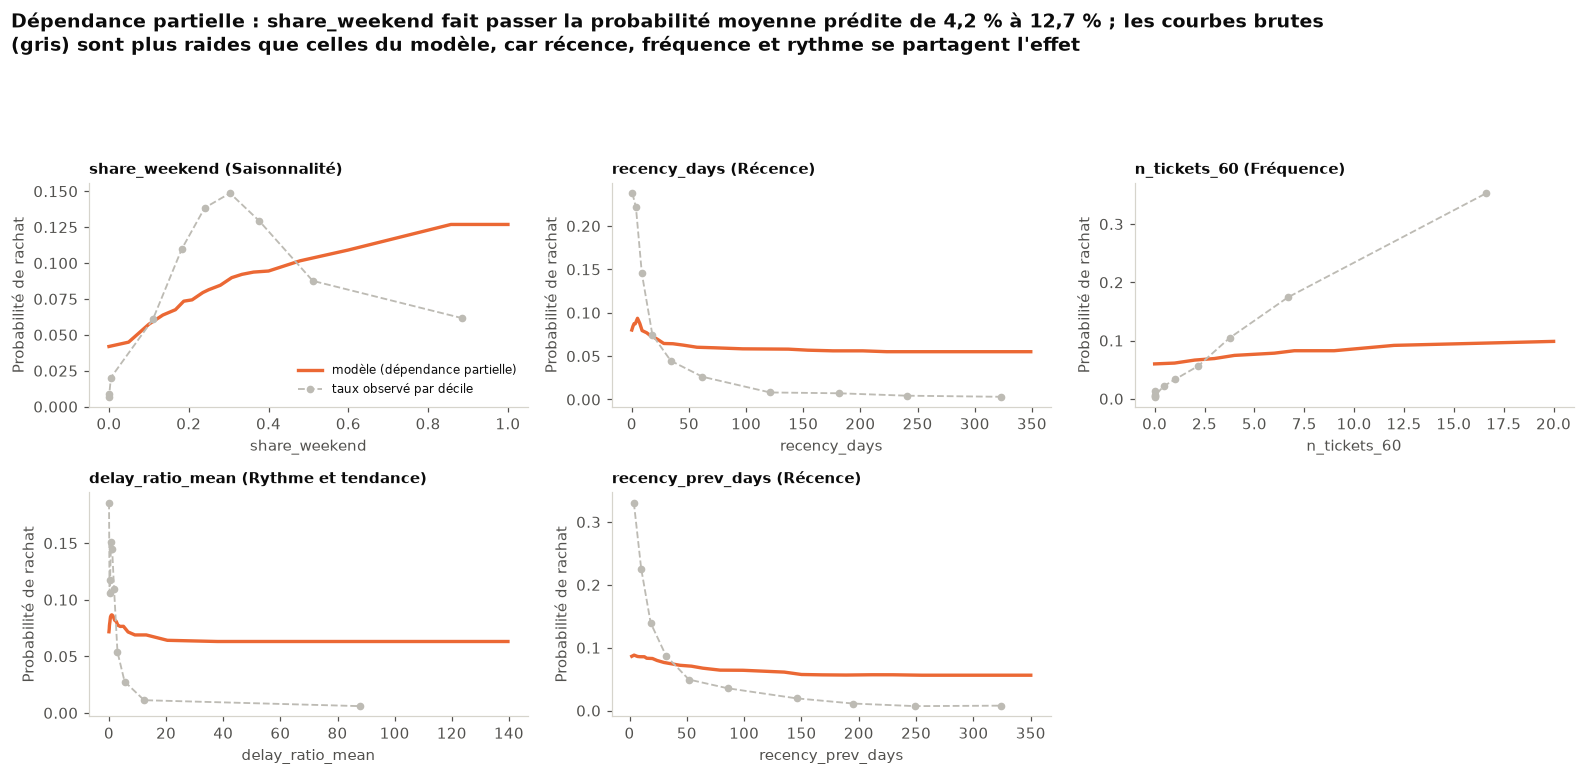

Dépendance partielle (probabilité moyenne prédite entre les valeurs extrêmes de la grille, centiles 2 % à 98 %) : `share_weekend` : de 4,2 % (0,0) à 12,7 % (1,0) ; `recency_days` : de 8,0 % (0,0) à 5,5 % (349,0) ; `n_tickets_60` : de 6,0 % (0,0) à 9,9 % (20,0) ; `delay_ratio_mean` : de 7,2 % (0,0) à 6,3 % (139,7) ; `recency_prev_days` : de 8,6 % (2,0) à 5,6 % (350,0). **Attention à la lecture** : la courbe grise est le taux de rachat brut par décile (corrélation, tous les autres facteurs mélangés) ; la courbe orange est l'effet moyen **de la variable seule** dans le modèle, les autres restant fixes. Les deux ne coïncident pas : récence, fréquence et rythme sont très corrélées et se partagent l'effet, donc chaque courbe du modèle est plus plate que la courbe brute ; et pour `share_weekend` la courbe brute est en cloche (les clients purement « week-end » sont surtout des clients occasionnels) alors que l'effet du modèle, à situation comparable, est croissant. Des combinaisons irréalistes entrent aussi dans la moyenne : lecture qualitative seulement.

In [22]:
# Dépendance partielle : les 5 variables numériques non binaires les plus importantes par permutation
cand = [k for k in perm.index if k not in cat_cols and Xtr_raw[k].nunique() > 2][:5]
Ap = A0_va[np.random.RandomState(1).choice(len(A0_va), 5000, replace=False)]
Xv0 = Xtr_raw.loc[folds.index[va0]]
fig, axs = plt.subplots(2, 3, figsize=(14.5, 7)); axs = axs.ravel()
PDP = {}
for ax, k in zip(axs, cand):
    j = ENC_COLS.index(k); xs = Xtr_raw[k].dropna()
    grid = np.unique(np.quantile(xs, np.linspace(.02, .98, 25)))
    pd_v = []
    for g in grid:
        Ab = Ap.copy(); Ab[:, j] = g; pd_v.append(m0.predict_proba(Ab)[:, 1].mean())
    PDP[k] = (grid, np.array(pd_v))
    ax.plot(grid, pd_v, color=c.ACCENT, lw=2.2, label='modèle (dépendance partielle)')
    q = pd.qcut(Xv0[k].rank(method='first'), 10, labels=False); emp = pd.DataFrame({'x': Xv0[k].to_numpy(), 'y': y0_va, 'q': q.to_numpy()}).groupby('q').mean()
    ax.plot(emp['x'], emp['y'], marker='o', ls='--', color=c.GREY, lw=1.2, ms=4, label='taux observé par décile')
    ax.set_xlabel(k); ax.set_ylabel('Probabilité de rachat'); ax.set_title(f"{k} ({fam_of(k)})", fontsize=9.5, loc='left')
axs[0].legend(frameon=False, fontsize=8)
for ax in axs[len(cand):]:
    ax.axis('off')
k0 = cand[0]
done(fig, '04_dependance_partielle', f"Dépendance partielle : {k0} fait passer la probabilité moyenne prédite de {fr(100 * PDP[k0][1][0], 1)} % à {fr(100 * PDP[k0][1][-1], 1)} % ; les courbes brutes (gris) sont plus raides que celles du modèle, car récence, fréquence et rythme se partagent l'effet")
pdp_txt = ' ; '.join(f"`{k}` : de {fr(100 * v[1][0], 1)} % ({fr(v[0][0], 1)}) à {fr(100 * v[1][-1], 1)} % ({fr(v[0][-1], 1)})" for k, v in PDP.items())
md(f'''Dépendance partielle (probabilité moyenne prédite entre les valeurs extrêmes de la grille, centiles 2 % à 98 %) : {pdp_txt}. **Attention à la lecture** : la courbe grise est le taux de rachat brut par décile (corrélation, tous les autres facteurs mélangés) ; la courbe orange est l'effet moyen **de la variable seule** dans le modèle, les autres restant fixes. Les deux ne coïncident pas : récence, fréquence et rythme sont très corrélées et se partagent l'effet, donc chaque courbe du modèle est plus plate que la courbe brute ; et pour `share_weekend` la courbe brute est en cloche (les clients purement « week-end » sont surtout des clients occasionnels) alors que l'effet du modèle, à situation comparable, est croissant. Des combinaisons irréalistes entrent aussi dans la moyenne : lecture qualitative seulement.''')

In [23]:
fam_top = fam_gain['LightGBM'].head(3)
perm_top = perm.head(8)
n_we_aug = int((pd.date_range('2020-08-01', '2020-08-31').dayofweek >= 5).sum())
low_fams = [g for g in abl.index if g in GROUPS and abs(abl.loc[g, 'perte_moy_plis']) <= .0005]
md(f'''**Lecture marketing.**
- **Le signal est dans l'activité récente.** Les familles `{fam_top.index[0]}` ({pc(fam_top.iloc[0])} du gain de LightGBM) et `{fam_top.index[1]}` ({pc(fam_top.iloc[1])}) portent l'essentiel du gain : un client rachète surtout parce qu'il a acheté souvent et récemment (nombre de tickets sur 60 et 180 jours, temps depuis les deux derniers achats). Le LightGBM combine ces indicateurs entre eux, ce que la règle de récence ne fait pas : le rappel du top 10 % passe de {pc(rep_rec['recall_top10'])} à {pc(bn['recall_top10'])}.
- **Un résultat qui mérite d'être vérifié : la part d'achats le week-end.** La permutation (`{perm.index[0]}` en tête, loin devant `{perm.index[1]}`) et l'ablation (famille `{worst}`, seule famille dont le retrait coûte de l'AUC) la placent au premier plan, alors que le gain la classe derrière la fréquence. Une hypothèse : août 2020 commence un samedi et compte {n_we_aug} jours de week-end sur 31 ; les clients qui achètent surtout le week-end ont plus d'occasions de racheter ce mois-là. Avec un seul mois cible, on ne peut pas séparer un vrai comportement d'un effet de calendrier propre à août 2020 : à tester avec d'autres coupures (phase d'optimisation) avant de bâtir une recommandation dessus.
- **Les autres familles sont redondantes ou faibles** : {', '.join(f'`{g}`' for g in low_fams if g in ('Récence', 'Fréquence', 'Rythme et tendance'))} se recouvrent (retirée seule, l'une est remplacée par les autres) ; {', '.join(f'`{g}`' for g in low_fams if g not in ('Récence', 'Fréquence', 'Rythme et tendance'))} n'apportent rien de mesurable : le retrait de chacune ne change l'AUC que de 0,0005 au plus. Le profil d'identité (e-mail, département, civilité) n'est pas nécessaire ({sg(prof['perte_moy_plis'])} d'AUC sans lui) : s'en passer évite un risque de proxy d'âge et de territoire sans perte sensible.
- **Usage** : le score est un **classement** (voir la calibration) ; pour la campagne, on cible le top 10 % et on pilote par test A/B (notebook 07).
''')

**Lecture marketing.**
- **Le signal est dans l'activité récente.** Les familles `Fréquence` (46,5 % du gain de LightGBM) et `Récence` (22,1 %) portent l'essentiel du gain : un client rachète surtout parce qu'il a acheté souvent et récemment (nombre de tickets sur 60 et 180 jours, temps depuis les deux derniers achats). Le LightGBM combine ces indicateurs entre eux, ce que la règle de récence ne fait pas : le rappel du top 10 % passe de 30,4 % à 52,6 %.
- **Un résultat qui mérite d'être vérifié : la part d'achats le week-end.** La permutation (`share_weekend` en tête, loin devant `recency_days`) et l'ablation (famille `Saisonnalité`, seule famille dont le retrait coûte de l'AUC) la placent au premier plan, alors que le gain la classe derrière la fréquence. Une hypothèse : août 2020 commence un samedi et compte 10 jours de week-end sur 31 ; les clients qui achètent surtout le week-end ont plus d'occasions de racheter ce mois-là. Avec un seul mois cible, on ne peut pas séparer un vrai comportement d'un effet de calendrier propre à août 2020 : à tester avec d'autres coupures (phase d'optimisation) avant de bâtir une recommandation dessus.
- **Les autres familles sont redondantes ou faibles** : `Rythme et tendance`, `Récence`, `Fréquence` se recouvrent (retirée seule, l'une est remplacée par les autres) ; `Magasins`, `Profil client`, `Segment de prix`, `Promotions et retours`, `Montant`, `Paiement` n'apportent rien de mesurable : le retrait de chacune ne change l'AUC que de 0,0005 au plus. Le profil d'identité (e-mail, département, civilité) n'est pas nécessaire (−0,0002 d'AUC sans lui) : s'en passer évite un risque de proxy d'âge et de territoire sans perte sensible.
- **Usage** : le score est un **classement** (voir la calibration) ; pour la campagne, on cible le top 10 % et on pilote par test A/B (notebook 07).


## 8. Sauvegarde des prédictions, des hyperparamètres et de la soumission

Pour chaque modèle retenu : prédictions hors-échantillon du train (`oof`) et prédiction du test = **moyenne des 5 modèles de pli** (ou ré-ajustement sur tout le train : non fait ici ; la moyenne évite un 6e entraînement et reste cohérente avec l'évaluation). La soumission n'est écrite que pour le meilleur modèle **de ce notebook**, sans envoi à Kaggle ; le choix du modèle final se fait au notebook 06.

In [24]:
for nm in MAIN:
    c.save_predictions(nm, RESULTS[nm]['oof'], RESULTS[nm]['test'])
# contrôle : relecture et cohérence
o, t = c.load_predictions(BEST_NAME)
assert o.index.equals(y.index) and len(t) == len(Xte_raw) and np.isclose(roc_auc_score(yv, o), comp.loc[BEST_NAME, 'auc'])
thr = np.quantile(o, 1 - c.TOP_FRAC)

best_params = {
    'protocole': {'folds': 'c.get_folds() (5 plis)', 'sous_echantillon_recherche': int(SUB_N), 'plis_internes_recherche': 3, 'n_jobs': N_JOBS,
                  'random_search_configs': {'rf': N_ITER_RF, 'xgb_lgbm': N_ITER_GBM}, 'grid_search': {'learning_rate': LR_GRID, 'cles': 'taille des arbres x taille minimale des feuilles'},
                  'nb_arbres_gbm': 'arrêt anticipé sur le pli 0 (jeu complet), puis fixé en CV'},
    'rf_tuned': RF_TUNED,
    'xgb_tuned': TUNED['xgb'],
    'lgbm_tuned': TUNED['lgbm'],
    'desequilibre': {'scale_pos_weight_rapport_complet': float(ratio), 'class_weight_rf': 'balanced_subsample', 'retenu_pour_le_meilleur_modele': False},
    'meilleur_modele_notebook_04': {'nom': BEST_NAME, 'auc': float(comp.loc[BEST_NAME, 'auc']), 'params': RESULTS[BEST_NAME]['params']},
    'variables': {'jumeaux_log_retires': len(log_cols), 'colonnes_encodees': len(ENC_COLS), 'variables_profil_identite': PROFILE_VARS},
}
c.save_result('04_best_params', best_params)
sub_path = c.write_submission(RESULTS[BEST_NAME]['test'], f'04_best_{BEST_NAME}')
chk = pd.read_csv(sub_path)
md(f'''{len(MAIN)} jeux de prédictions enregistrés (`{'`, `'.join(MAIN)}`), hyperparamètres dans `results/04_best_params.json`. Soumission du meilleur modèle : `{sub_path.name}` ({nf(len(chk))} lignes, colonnes `{'`, `'.join(chk.columns)}`) ; **non envoyée à Kaggle**.

Contrôle de cohérence du test pour `{BEST_NAME}` : score moyen hors-échantillon du train **{a4(o.mean())}**, score moyen du test **{a4(t.mean())}** ; part du test au-dessus du seuil du top 10 % du train : **{pc((t >= thr).mean())}** (attendu : environ 10 %).
''')

10 jeux de prédictions enregistrés (`rf_default`, `rf_tuned`, `rf_tuned_cw`, `xgb_default`, `xgb_tuned`, `xgb_tuned_spw`, `lgbm_default`, `lgbm_tuned`, `lgbm_tuned_spw`, `lgbm_no_profile`), hyperparamètres dans `results/04_best_params.json`. Soumission du meilleur modèle : `04_best_lgbm_tuned.csv` (40 106 lignes, colonnes `ID`, `Expected`) ; **non envoyée à Kaggle**.

Contrôle de cohérence du test pour `lgbm_tuned` : score moyen hors-échantillon du train **0,0769**, score moyen du test **0,0775** ; part du test au-dessus du seuil du top 10 % du train : **10,0 %** (attendu : environ 10 %).


## 9. Limites et pistes d'amélioration

**Ce qui limite la portée des chiffres**
- **Réglage sur les mêmes plis.** Le sous-échantillon de recherche (40 000 clients) est tiré dans les 5 plis, et le nombre d'arbres final est choisi sur le pli 0 : l'AUC hors-échantillon est donc **légèrement optimiste** (les validations ont « vu » le réglage). L'ordre de grandeur du biais est faible (le réglage gagne peu pour LightGBM, davantage pour XGBoost et la forêt), mais seule une validation croisée imbriquée ou un jeu de validation tenu à l'écart l'éliminerait. Le test Kaggle sera le premier juge indépendant.
- **Plis aléatoires, une seule coupure** (cible = août 2020 seul) : pas de test de stabilité dans le temps, pas de saisonnalité apprenable ; la dérive d'une année sur l'autre n'est pas mesurée.
- **Les scores sont des classements, pas des probabilités mensuelles** : la cible est plus étroite que « acheter dans le mois » (notebook 01). Les modèles pondérés (`class_weight`, `scale_pos_weight`) dégradent encore la calibration ; si une probabilité est nécessaire, recalibrer (régression isotonique ou logistique sur le score).
- **Forêt de scikit-learn** : l'imputation par la médiane écrase l'information « non défini » pour les variables sans indicateur dédié ; les versions récentes savent traiter les manquants nativement (non utilisé, pour rester dans le cours).
- **Importances et dépendance partielle** : variables très corrélées, importances partagées ; SHAP au notebook 06.

**Ce qui n'a pas apporté grand-chose** : le réglage fin de LightGBM, les jumeaux log (invariants pour les arbres), les variables de montant, de paiement, de magasin et de profil (retrait sans perte mesurable). Le gain majeur vient de la table de variables (notebook 02), pas de l'algorithme.

**Un effet à ne pas surinterpréter** : la part d'achats le week-end pèse beaucoup dans le modèle ; avec une seule coupure (août 2020, qui commence un samedi) on ne sait pas s'il s'agit d'un comportement durable ou d'un effet de calendrier.

**Pistes pour la phase d'optimisation Kaggle** (non implémentées ici)
- **Catégories natives de LightGBM** pour `dept`, `email_domain`, `main_store_region` à la place du one-hot (moins de colonnes, regroupement optimal des modalités).
- **Nouvelles fenêtres et interactions** : fenêtres de 3 et 10 jours, décroissances exponentielles de la fréquence, ratios récence / rythme habituel, jours depuis le dernier jour de semaine habituel d'achat.
- **Cibles décalées / multi-coupures** pour augmenter le nombre de lignes d'entraînement (autres mois comme « août ») et stabiliser les modèles ; données ouvertes (INSEE par commune, calendrier, météo).
- **Plus d'essais de réglage** (budget de calcul ; plus de configurations de random search, plis internes plus nombreux), `max_bin`, régularisation, profondeur par arbre ; moyenne de graines.
- **Validation** : plis groupés dans le temps, validation croisée imbriquée.

In [25]:
# Temps de calcul par étape
st = pd.Series(STEP_TIMES).rename('secondes').to_frame()
st['minutes'] = st['secondes'] / 60
display(st.style.format({'secondes': '{:.0f}', 'minutes': '{:.1f}'}))
md(f"Temps de calcul total des étapes chronométrées : **{st['secondes'].sum() / 60:.1f} min** (5 cœurs).")

,secondes,minutes
RF : forêt non réglée (CV 5 plis),30,0.5
RF : random search (sous-échantillon),164,2.7
RF : courbe du nombre d'arbres,82,1.4
RF : forêt réglée (CV 5 plis),99,1.7
RF : forêt réglée + class_weight (CV 5 plis),92,1.5
GBM : modèles non réglés (CV 5 plis),16,0.3
LightGBM : random search (sous-échantillon),38,0.6
XGBoost : random search (sous-échantillon),188,3.1
LightGBM : grid search fin,45,0.7
XGBoost : grid search fin,312,5.2


Temps de calcul total des étapes chronométrées : **28.2 min** (5 cœurs).

In [26]:
# ---------- résumé écrit pour le deck et l'oral ----------
L = []
def rowtxt(n):
    r = comp.loc[n]; return f"`{n}` : AUC {a4(r['auc'])} (plis {a4(r['auc_fold_mean'])} ± {a4(r['auc_fold_std'])}), lift {fr(r['lift_top10'], 2)}, log-loss {a4(r['logloss'])}, {fr(r['fit_seconds'], 1)} s/pli"
bp = best_params['meilleur_modele_notebook_04']['params']
L += ['# Résumé du notebook 04 : forêts aléatoires et gradient boosting', '', '## Chiffres clés (train, 5 plis communs, hors-échantillon ; top 10 % = les 10 % de clients au meilleur score)']
L += [f"- Repère : règle de récence seule, AUC {a4(rep_rec['auc'])}, précision {pc(rep_rec['precision_top10'])}, rappel {pc(rep_rec['recall_top10'])}, lift {fr(rep_rec['lift_top10'], 2)} dans le top 10 %."]
for n in ('rf_default', 'rf_tuned', 'xgb_default', 'xgb_tuned', 'lgbm_default', 'lgbm_tuned'):
    L.append('- ' + rowtxt(n))
L += [f"- **Meilleur modèle du notebook : `{BEST_NAME}`**, AUC {a4(bn['auc'])}, top 10 % : précision {pc(bn['precision_top10'])}, rappel {pc(bn['recall_top10'])}, lift {fr(bn['lift_top10'], 2)} ; hyperparamètres `{json.dumps(bp, ensure_ascii=False, default=str)}`. Écart avec le suivant (`{second}`) : {sg(dd.mean())} d'AUC, très inférieur à l'écart-type entre plis ({a4(bn['auc_fold_std'])}).",
      f"- Déséquilibre : pondérer les rachats (rapport complet) donne AUC {a4(comp.loc['lgbm_tuned_spw', 'auc'])} contre {a4(comp.loc['lgbm_tuned', 'auc'])} pour LightGBM mais log-loss {a4(comp.loc['lgbm_tuned_spw', 'logloss'])} contre {a4(comp.loc['lgbm_tuned', 'logloss'])} : classement identique, probabilités faussées (score moyen = {fr(CS['lgbm_tuned_spw']['mean_ratio'], 1)} × le taux réel).",
      f"- Ablation (LightGBM, perte d'AUC moyenne par pli) : " + ' ; '.join(f"{i} {sg(v)}" for i, v in fam_loss.head(3).items()) + f" ; les autres familles ≤ 0,0005 ; `share_weekend` + `share_saturday` seules : {sg(wk['perte_moy_plis'])} ; profil d'identité {sg(prof['perte_moy_plis'])} (sans profil : AUC {a4(lgb_np['rep']['auc'])} vs {a4(lgb_tun['rep']['auc'])}).",
      f"- Variables principales (gain LightGBM) : {', '.join(gain['lgbm'].index[:10])} ; par permutation : {', '.join(perm.index[:5])}.",
      f"- Calcul : {st['secondes'].sum() / 60:.0f} min d'étapes chronométrées (5 cœurs, machine partagée : les durées varient beaucoup avec la charge) ; sous-échantillon de recherche {nf(SUB_N)} clients ; {len(log_cols)} jumeaux log retirés, {len(ENC_COLS)} colonnes après one-hot."]
L += ['', '## Figures (message)']
for k, v in FIG_MSG.items():
    L.append(f'- `figures/{k}.png` : {v}')
L += ['', '## Décisions méthodologiques',
      f"- Mêmes 5 plis pour tous les modèles ; test = moyenne des 5 modèles de pli ; le test ne sert à aucune décision. Réglage : random search ({N_ITER_GBM} configurations GBM, {N_ITER_RF} forêt) puis grid fin (slide 69), sur un sous-échantillon stratifié de {nf(SUB_N)} clients (3 plis internes) ; pas d'optimisation bayésienne ni de stacking.",
      f"- {len(log_cols)} jumeaux `log_*` retirés (arbres invariants aux transformations monotones : AUC {a4(auc_nolog)} sans vs {a4(auc_log)} avec). One-hot N − 1 des 6 qualitatives pour tous les modèles ; manquants natifs pour XGBoost / LightGBM, médiane + indicateurs pour la forêt.",
      '- Nombre d\'arbres du boosting fixé par arrêt anticipé sur le pli 0 puis figé dans la CV ; courbes de validation pour montrer sur-apprentissage et plateau.',
      '- Soumission écrite pour le meilleur modèle de ce notebook seulement, non envoyée à Kaggle ; choix final au notebook 06.']
L += ['', '## Anomalies et points de vigilance',
      '- Le réglage (même léger) utilise les mêmes plis que l\'évaluation : AUC hors-échantillon légèrement optimiste ; sous-échantillon de recherche tiré dans tous les plis.',
      '- Les scores sont des classements : cible plus étroite que « acheter dans le mois » ; la pondération des rachats détériore encore la calibration.',
      f"- Profil d'identité (e-mail, département, civilité) : coût d'AUC {sg(prof['perte_moy_plis'])} en le retirant ; risque de proxy d'âge et de territoire (RGPD, discrimination indirecte).",
      '', '## Limites et pistes (phase d\'optimisation Kaggle)',
      '- Catégories natives de LightGBM ; nouvelles fenêtres (3 et 10 jours, décroissances exponentielles) et ratios ; cibles décalées / multi-coupures ; open data INSEE, calendrier, météo.',
      '- Plus d\'essais de réglage, graines multiples, validation imbriquée ou temporelle ; SHAP et profil du racheteur au notebook 06.']
L.insert(L.index('## Anomalies et points de vigilance') + 1, f"- La part d'achats le week-end (famille Saisonnalité) pèse beaucoup ; août 2020 commence un samedi et compte {n_we_aug} jours de week-end : effet de calendrier possible, non testable avec un seul mois cible.")
assert len(L) <= 60, len(L)
(c.RES / '04_summary.md').write_text('\n'.join(L) + '\n', encoding='utf-8')
md(f'`results/04_summary.md` écrit ({len(L)} lignes).')

`results/04_summary.md` écrit (45 lignes).